<a href="https://colab.research.google.com/github/pavllychka/mll2/blob/main/mll5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


<h1 style="margin:0;color:white">Лабораторна робота № 5–6</h1>
<h3 style="margin:6px 0 0 0;color:#dbe8f7;font-weight:400">Нейронна мережа (MLP з нуля) і регуляризація · FashionMNIST</h3>
</div>

| Блок | Зміст |
|:--|:--|
| **0** | Підготовка даних |
| **1** | MLP з нуля: forward, backprop, цикл навчання, gradient check, збереження ваг |
| **2** | Регуляризація: L2, L1, Dropout, weight/gradient clipping, L2 + Dropout |
| **3** | Зведені таблиці, гістограми, dead neurons vs accuracy, висновки |
| **✔** | Перевірка відповідності методичці (в кінці) |



In [1]:
# Автоматична перевірка та імпорт необхідних бібліотек (працює локально та в Google Colab)
import os
import sys
import gzip
import time
import warnings
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelsize': 10,
    'legend.frameon': False, 'lines.linewidth': 2,
})

# Єдиний стиль таблиць (pandas Styler / DataFrame)
from IPython.display import HTML, display
display(HTML('''<style>
table.dataframe th, .dataframe th {background:#1f3a5f !important;color:#fff !important;text-align:center !important}
table.dataframe td, .dataframe td {text-align:center}
table.dataframe tbody tr:nth-child(even) {background:#f3f7fb}
</style>'''))

print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version:  {np.__version__}")

Python version: 3.13.18
NumPy version:  2.4.6


---
## 1. Підготовка даних (FashionMNIST)

Згідно з методичними вказівками:
1. Як датасет використовується **FashionMNIST** (10 класів одягу та взуття, зображення $28 \times 28$ пікселів).
2. Зображення перетворюються на вектори розмірності $28 \cdot 28 = 784$, а значення пікселів нормалізуються до діапазону $[0, 1]$ діленням на $255.0$.
3. Для прискорення серії з понад 15 експериментів використовується фіксована стратифікована підмножина даних (**12 000** тренувальних, **3 000** валідаційних та **3 000** тестових зображень). Усі без винятку експерименти використовують **однакові підмножини даних** та однакову початкову ініціалізацію ваг (`SEED = 42`) для чесного порівняння.

In [2]:
# Завантаження FashionMNIST (пряме завантаження IDX-файлів із офіційного репозиторію Zalando або через scikit-learn)
import requests

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

FASHION_CLASSES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

def load_fashion_mnist(data_dir: Path):
    base_url = 'https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/'
    files = {
        'train_img': 'train-images-idx3-ubyte.gz',
        'train_lbl': 'train-labels-idx1-ubyte.gz',
        'test_img':  't10k-images-idx3-ubyte.gz',
        'test_lbl':  't10k-labels-idx1-ubyte.gz'
    }
    try:
        for fname in files.values():
            fpath = data_dir / fname
            if not fpath.exists():
                r = requests.get(base_url + fname, timeout=60)
                r.raise_for_status()
                fpath.write_bytes(r.content)

        with gzip.open(data_dir / files['train_img'], 'rb') as f:
            X_tr = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784).astype(np.float64) / 255.0
        with gzip.open(data_dir / files['train_lbl'], 'rb') as f:
            y_tr = np.frombuffer(f.read(), np.uint8, offset=8).astype(np.int64)
        with gzip.open(data_dir / files['test_img'], 'rb') as f:
            X_te = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784).astype(np.float64) / 255.0
        with gzip.open(data_dir / files['test_lbl'], 'rb') as f:
            y_te = np.frombuffer(f.read(), np.uint8, offset=8).astype(np.int64)
        return X_tr, y_tr, X_te, y_te
    except Exception as e:
        print(f"Пряме завантаження не вдалося ({e}), завантажуємо через fetch_openml...")
        from sklearn.datasets import fetch_openml
        fmnist = fetch_openml('Fashion-MNIST', version=1, as_frame=False, parser='auto')
        X_all = fmnist.data.astype(np.float64) / 255.0
        y_all = fmnist.target.astype(np.int64)
        return X_all[:60000], y_all[:60000], X_all[60000:], y_all[60000:]

X_full_train, y_full_train, X_full_test, y_full_test = load_fashion_mnist(DATA_DIR)

# Формуємо єдині фіксовані стратифіковані вибірки для всіх експериментів
X_train, X_val, y_train, y_val = train_test_split(
    X_full_train, y_full_train,
    train_size=12000, test_size=3000,
    stratify=y_full_train, random_state=SEED
)
_, X_test, _, y_test = train_test_split(
    X_full_test, y_full_test,
    test_size=3000,
    stratify=y_full_test, random_state=SEED
)

print(f"Повний датасет FashionMNIST: train={X_full_train.shape}, test={X_full_test.shape}")
print(f"Робочі вибірки (фіксовані для всіх експериментів):")
print(f"  X_train: {X_train.shape}, y_train: {y_train.shape}, діапазон значень: [{X_train.min():.1f}, {X_train.max():.1f}]")
print(f"  X_val:   {X_val.shape},   y_val:   {y_val.shape}")
print(f"  X_test:  {X_test.shape},  y_test:  {y_test.shape}")

Повний датасет FashionMNIST: train=(60000, 784), test=(10000, 784)
Робочі вибірки (фіксовані для всіх експериментів):
  X_train: (12000, 784), y_train: (12000,), діапазон значень: [0.0, 1.0]
  X_val:   (3000, 784),   y_val:   (3000,)
  X_test:  (3000, 784),  y_test:  (3000,)


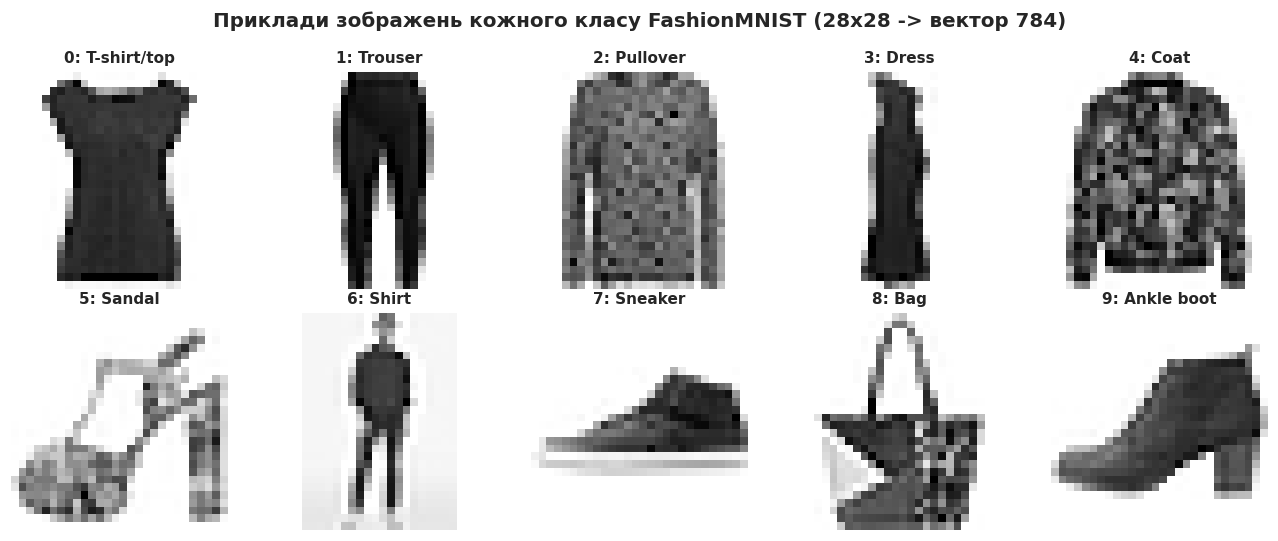

In [3]:
# Візуалізація прикладів із кожного класу FashionMNIST
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for cls_idx, ax in enumerate(axes.flat):
    sample_idx = np.where(y_train == cls_idx)[0][0]
    ax.imshow(X_train[sample_idx].reshape(28, 28), cmap='gray_r')
    ax.set_title(f"{cls_idx}: {FASHION_CLASSES[cls_idx]}", fontsize=10, fontweight='bold')
    ax.axis('off')
plt.suptitle("Приклади зображень кожного класу FashionMNIST (28x28 -> вектор 784)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 2. Блок 1. Реалізація нейронної мережі з нуля

### 2.1–2.3 Математична модель та архітектура MLP

Реалізуємо багатошаровий персептрон (**MLP**) із **3 прихованими шарами** та архітектурою:
$$\text{Input }(784) \longrightarrow \text{Dense }(256, \text{ReLU}) \longrightarrow \text{Dense }(128, \text{ReLU}) \longrightarrow \text{Dense }(64, \text{ReLU}) \longrightarrow \text{Output }(10, \text{Softmax})$$

1. **Прямий прохід (Forward pass)**:
   Для кожного шару $l \in \{1, \dots, L\}$:
   $$Z^{(l)} = A^{(l-1)} W^{(l)} + b^{(l)}, \qquad A^{(0)} = X$$
   Для прихованих шарів ($l < L$) застосовується функція активації **ReLU**:
   $$A^{(l)} = \text{ReLU}(Z^{(l)}) = \max(0, Z^{(l)})$$
   Якщо під час навчання увімкнено **Inverted Dropout** з імовірністю вимкнення нейрона $p$:
   $$M^{(l)} \sim \text{Bernoulli}(1 - p), \qquad \widetilde{A}^{(l)} = \frac{A^{(l)} \odot M^{(l)}}{1 - p}$$
   Для вихідного шару ($l = L$) використовується чисельно стабільний **Softmax**:
   $$P_i = \text{Softmax}(Z^{(L)}_i) = \frac{\exp(Z^{(L)}_i - \max_k Z^{(L)}_k)}{\sum_j \exp(Z^{(L)}_j - \max_k Z^{(L)}_k)}$$

2. **Функція втрат (Categorical Cross-Entropy + L1/L2 регуляризація)**:
   $$L = L_{\text{CE}} + \lambda_1 \sum_{l=1}^{L} \|W^{(l)}\|_1 + \frac{\lambda_2}{2} \sum_{l=1}^{L} \|W^{(l)}\|_2^2, \qquad L_{\text{CE}} = -\frac{1}{N} \sum_{i=1}^{N} \log p_{i, y_i}$$

3. **Зворотне поширення помилки (Backpropagation)**:
   Градієнт за логітами вихідного шару:
   $$\delta^{(L)} = \frac{\partial L_{\text{CE}}}{\partial Z^{(L)}} = \frac{P - Y}{N}$$
   Поширення помилки на приховані шари ($l = L-1, \dots, 1$):
   $$\delta^{(l)} = \left(\delta^{(l+1)} (W^{(l+1)})^T\right) \odot \mathbb{I}(Z^{(l)} > 0)$$
   *(За наявності Inverted Dropout під час навчання також множиться на $\frac{M^{(l)}}{1 - p}$).*
   Градієнти параметрів із урахуванням L1 (субградієнт $\text{sign}(0) = 0$) та L2:
   $$\frac{\partial L}{\partial W^{(l)}} = (A^{(l-1)})^T \delta^{(l)} + \lambda_2 W^{(l)} + \lambda_1 \text{sign}(W^{(l)}), \qquad \frac{\partial L}{\partial b^{(l)}} = \sum_{i=1}^{N} \delta^{(l)}_i$$

In [4]:
class MLP:
    """
    Повнозв'язна нейронна мережа (MLP), реалізована з нуля на NumPy.
    Підтримує:
      - Ініціалізацію ваг He (основна для ReLU) та Xavier
      - Прямий і зворотний проходи (ReLU + Softmax + Cross-Entropy)
      - Регуляризацію L1, L2, Inverted Dropout
      - Weight Clipping та Gradient Clipping (за глобальною L2-нормою)
      - Діагностику мертвих нейронів (dead neurons) та розрідженості ваг (sparsity)
      - Збереження та відновлення параметрів (save_weights / load_weights)
    """
    def __init__(
        self,
        layer_sizes=(784, 256, 128, 64, 10),
        init_method='he',
        l1_lambda=0.0,
        l2_lambda=0.0,
        dropout_p=0.0,
        weight_clip=None,
        grad_clip=None,
        seed=42
    ):
        self.layer_sizes = list(layer_sizes)
        self.num_layers = len(self.layer_sizes) - 1
        self.init_method = init_method
        self.l1_lambda = float(l1_lambda)
        self.l2_lambda = float(l2_lambda)
        self.dropout_p = float(dropout_p)
        self.weight_clip = weight_clip
        self.grad_clip = grad_clip
        self.seed = seed

        self.rng = np.random.default_rng(seed)
        self.weights = []
        self.biases = []
        self._init_parameters()

        # Проміжні значення для backpropagation
        self.activations = []
        self.z_values = []
        self.dropout_masks = []

    def _init_parameters(self):
        """Ініціалізація ваг за методом He (формула 13) або Xavier (формула 14)."""
        self.weights = []
        self.biases = []
        for i in range(self.num_layers):
            n_in = self.layer_sizes[i]
            n_out = self.layer_sizes[i + 1]
            if self.init_method.lower() == 'he':
                # He initialization: W ~ N(0, 2 / n_in)
                W = self.rng.normal(loc=0.0, scale=np.sqrt(2.0 / n_in), size=(n_in, n_out))
            elif self.init_method.lower() == 'xavier':
                # Xavier uniform initialization: W ~ U(-sqrt(6/(n_in+n_out)), sqrt(6/(n_in+n_out)))
                limit = np.sqrt(6.0 / (n_in + n_out))
                W = self.rng.uniform(low=-limit, high=limit, size=(n_in, n_out))
            else:
                raise ValueError(f"Невідомий метод ініціалізації: {self.init_method}")
            b = np.zeros(n_out, dtype=np.float64)
            self.weights.append(W)
            self.biases.append(b)

    def forward(self, X, training=False):
        """
        Прямий прохід нейронної мережі (п. 2.2 методички + Inverted Dropout з п. 1.6).
        Приймає батч об'єктів X (N, D) та повертає матрицю ймовірностей класів P (N, C).
        """
        self.activations = [X]
        self.z_values = []
        self.dropout_masks = []

        A = X

        # Приховані шари з активацією ReLU
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b
            A = np.maximum(0.0, Z)

            # Inverted Dropout застосовується лише під час навчання (training=True)
            if training and self.dropout_p > 0.0:
                mask = (self.rng.random(size=A.shape) >= self.dropout_p).astype(np.float64)
                A = (A * mask) / (1.0 - self.dropout_p)
                self.dropout_masks.append(mask)
            else:
                self.dropout_masks.append(None)

            self.z_values.append(Z)
            self.activations.append(A)

        # Вихідний шар із чисельно стабільним Softmax
        Z_out = A @ self.weights[-1] + self.biases[-1]
        Z_shifted = Z_out - np.max(Z_out, axis=1, keepdims=True)
        exp_Z = np.exp(Z_shifted)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

        self.z_values.append(Z_out)
        self.activations.append(P)

        return P

    def compute_loss(self, y_true, P=None):
        """
        Обчислення Categorical Cross-Entropy (формула 5) та повного Loss із L1/L2 штрафами (формули 18, 19).
        Повертає кортеж: (total_loss, ce_loss).
        """
        if P is None:
            P = self.activations[-1]
        n = y_true.shape[0]
        eps = 1e-12
        correct_probs = np.clip(P[np.arange(n), y_true], eps, 1.0)
        ce_loss = -np.mean(np.log(correct_probs))

        reg_loss = 0.0
        if self.l1_lambda > 0.0:
            reg_loss += self.l1_lambda * sum(np.sum(np.abs(W)) for W in self.weights)
        if self.l2_lambda > 0.0:
            reg_loss += 0.5 * self.l2_lambda * sum(np.sum(W ** 2) for W in self.weights)

        return ce_loss + reg_loss, ce_loss

    def backward(self, y_true):
        """
        Зворотне поширення помилки (п. 2.3 методички) з урахуванням L1/L2 та Dropout.
        """
        n = y_true.shape[0]

        grads_W = [None] * len(self.weights)
        grads_b = [None] * len(self.biases)

        # Градієнт Softmax + Cross Entropy за логітами вихідного шару (формула 6)
        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1.0
        delta /= n

        for l in reversed(range(len(self.weights))):
            A_prev = self.activations[l]

            # Базові градієнти за вагами та зміщеннями (формули 9, 10)
            gW = A_prev.T @ delta
            gb = np.sum(delta, axis=0)

            # Додавання градієнтів регуляризації L2 (формула 33) та L1 (формула 35, субградієнт sign(0)=0)
            if self.l2_lambda > 0.0:
                gW = gW + self.l2_lambda * self.weights[l]
            if self.l1_lambda > 0.0:
                gW = gW + self.l1_lambda * np.sign(self.weights[l])

            grads_W[l] = gW
            grads_b[l] = gb

            # Поширення градієнта на попередній прихований шар (формули 7, 8)
            if l > 0:
                delta = delta @ self.weights[l].T
                if self.dropout_masks[l - 1] is not None:
                    delta = (delta * self.dropout_masks[l - 1]) / (1.0 - self.dropout_p)
                delta *= (self.z_values[l - 1] > 0.0)

        return grads_W, grads_b

    def step(self, grads_W, grads_b, lr):
        """
        Оновлення параметрів за допомогою SGD (формули 11, 12),
        із підтримкою Gradient Clipping (формула 38) та Weight Clipping (формула 37).
        Повертає глобальну L2-норму градієнта до обрізання.
        """
        # Обчислення глобальної L2-норми градієнтів
        total_norm_sq = sum(np.sum(gW ** 2) for gW in grads_W) + sum(np.sum(gb ** 2) for gb in grads_b)
        grad_norm = np.sqrt(total_norm_sq)

        # Gradient clipping (формула 23 / 38)
        scale = 1.0
        if self.grad_clip is not None and grad_norm > 0.0:
            scale = min(1.0, self.grad_clip / grad_norm)

        for l in range(self.num_layers):
            self.weights[l] -= lr * (grads_W[l] * scale)
            self.biases[l]  -= lr * (grads_b[l] * scale)

            # Weight clipping після кожного кроку оновлення (формула 22 / 37)
            if self.weight_clip is not None:
                c_val = float(self.weight_clip)
                self.weights[l] = np.clip(self.weights[l], -c_val, c_val)

        return grad_norm

    def predict_proba(self, X):
        """Передбачення ймовірностей у режимі inference (Dropout вимкнено)."""
        return self.forward(X, training=False)

    def predict(self, X):
        """Передбачення класів у режимі inference."""
        return np.argmax(self.predict_proba(X), axis=1)

    def evaluate(self, X, y):
        """Повертає (accuracy, ce_loss, total_loss) на вибірці (X, y) у режимі inference."""
        P = self.predict_proba(X)
        total_loss, ce_loss = self.compute_loss(y, P)
        preds = np.argmax(P, axis=1)
        acc = np.mean(preds == y)
        return acc, ce_loss, total_loss

    def diagnose_dead_neurons(self, X_data):
        """
        Діагностика мертвих нейронів (п. 1.4 та п. 3.2 методички, формули 30, 31).
        Виконується строго в режимі inference (training=False, Dropout вимкнено).
        Нейрон вважається мертвим, якщо max_i Z^(l)_{ij} <= 0 на всій тренувальній вибірці.
        """
        _ = self.forward(X_data, training=False)
        layer_stats = []
        total_dead = 0
        total_neurons = 0

        for l_idx in range(self.num_layers - 1):
            Z_l = self.z_values[l_idx]  # (N, n_neurons)
            max_z = np.max(Z_l, axis=0)
            n_dead = int(np.sum(max_z <= 0.0))
            n_neurons = int(Z_l.shape[1])
            pct_dead = (n_dead / n_neurons) * 100.0

            total_dead += n_dead
            total_neurons += n_neurons
            layer_stats.append({
                'Шар': f'Hidden {l_idx + 1} ({n_neurons})',
                'Кількість нейронів': n_neurons,
                'Мертвих нейронів (N_dead)': n_dead,
                'Частка мертвих (D_l), %': pct_dead
            })

        overall_pct = (total_dead / total_neurons) * 100.0 if total_neurons > 0 else 0.0
        return layer_stats, overall_pct, total_dead, total_neurons

    def compute_sparsity(self, threshold=0.01):
        """
        Обчислення розрідженості ваг (п. 1.8 методички, формула 24):
        S = #{|W_ij| < 0.01} / #W_ij * 100%
        Оцінюється для прихованих шарів та для всієї мережі.
        """
        all_w = np.concatenate([W.ravel() for W in self.weights[:-1]])
        sparse_count = np.sum(np.abs(all_w) < threshold)
        return (sparse_count / all_w.size) * 100.0

    def save_weights(self, path):
        """Збереження усіх ваг, зміщень та конфігурації моделі у файл .npz (п. 2.6 методички)."""
        data = {
            'layer_sizes': np.array(self.layer_sizes, dtype=np.int64),
            'num_layers': np.array(self.num_layers, dtype=np.int64),
            'init_method': np.array(self.init_method),
            'l1_lambda': np.array(self.l1_lambda, dtype=np.float64),
            'l2_lambda': np.array(self.l2_lambda, dtype=np.float64),
            'dropout_p': np.array(self.dropout_p, dtype=np.float64),
            'weight_clip': np.array(np.nan if self.weight_clip is None else self.weight_clip, dtype=np.float64),
            'grad_clip': np.array(np.nan if self.grad_clip is None else self.grad_clip, dtype=np.float64),
            'seed': np.array(self.seed, dtype=np.int64)
        }
        for i, W in enumerate(self.weights):
            data[f'W_{i}'] = W
        for i, b in enumerate(self.biases):
            data[f'b_{i}'] = b
        np.savez(path, **data)

    def load_weights(self, path):
        """Завантаження збережених ваг, зміщень та конфігурації у екземпляр мережі (п. 2.6 методички)."""
        data = np.load(path, allow_pickle=False)
        if 'layer_sizes' in data:
            self.layer_sizes = data['layer_sizes'].tolist()
            self.num_layers = len(self.layer_sizes) - 1
        if 'init_method' in data:
            self.init_method = str(data['init_method'])
        for key in ('l1_lambda', 'l2_lambda', 'dropout_p'):
            if key in data:
                setattr(self, key, float(data[key]))
        for key in ('weight_clip', 'grad_clip'):
            if key in data:
                v = float(data[key])
                setattr(self, key, None if np.isnan(v) else v)
        if 'seed' in data:
            self.seed = int(data['seed'])
        self.weights = [data[f'W_{i}'].copy() for i in range(self.num_layers)]
        self.biases  = [data[f'b_{i}'].copy() for i in range(self.num_layers)]

---
### 2.4 Цикл навчання нейронної мережі

Реалізуємо повний цикл навчання (`train_model`), який на кожній епосі:
1. Перемішує тренувальні дані (`shuffle`);
2. Ділить вибірку на мінібатчі (`batch_size = 128`);
3. Виконує прямий прохід (`forward(X_batch, training=True)`);
4. Обчислює функцію втрат (`compute_loss`);
5. Виконує зворотне поширення помилки (`backward(y_batch)`);
6. Оновлює ваги та зміщення за допомогою `SGD` (`step`);
7. Оцінює якість моделі (`loss` та `accuracy`) на тренувальній і валідаційній вибірках у режимі `inference`.

In [5]:
# Збережемо початковий розподіл ваг після He initialization для подальшого порівняння (п. 4.2)
ARCH = (784, 256, 128, 64, 10)
init_ref_model = MLP(layer_sizes=ARCH, init_method='he', seed=SEED)
INITIAL_WEIGHTS_FLAT = np.concatenate([W.ravel().copy() for W in init_ref_model.weights[:-1]])
INITIAL_WEIGHTS_BY_LAYER = [W.copy() for W in init_ref_model.weights[:-1]]

def train_model(
    model: MLP,
    X_tr, y_tr,
    X_va, y_va,
    epochs=35,
    batch_size=128,
    lr=0.05,
    verbose=True
):
    n_samples = X_tr.shape[0]
    rng = np.random.default_rng(model.seed + 100)

    history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': [],
        'grad_norm_mean': [],
        'grad_norm_max': [],
        'batch_losses': []
    }

    t0 = time.time()
    for epoch in range(1, epochs + 1):
        # 1. Перемішування тренувальних даних
        perm = rng.permutation(n_samples)
        X_shuf = X_tr[perm]
        y_shuf = y_tr[perm]

        epoch_grad_norms = []
        # 2. Поділ на мінібатчі
        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            xb = X_shuf[start:end]
            yb = y_shuf[start:end]

            # 3. Прямий прохід
            P_batch = model.forward(xb, training=True)
            # 4. Обчислення функції втрат
            _, ce_b = model.compute_loss(yb, P_batch)
            history['batch_losses'].append(ce_b)
            # 5. Зворотне поширення помилки
            grads_W, grads_b = model.backward(yb)
            # 6. Оновлення ваг та зміщень
            g_norm = model.step(grads_W, grads_b, lr=lr)
            epoch_grad_norms.append(g_norm)

        # 7. Оцінювання якості на тренувальній і валідаційній вибірках (у режимі inference)
        tr_acc, tr_ce, _ = model.evaluate(X_tr, y_tr)
        va_acc, va_ce, _ = model.evaluate(X_va, y_va)

        history['train_loss'].append(tr_ce)
        history['val_loss'].append(va_ce)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)
        history['grad_norm_mean'].append(float(np.mean(epoch_grad_norms)))
        history['grad_norm_max'].append(float(np.max(epoch_grad_norms)))

        if verbose and (epoch == 1 or epoch % 7 == 0 or epoch == epochs):
            print(f"Епоха {epoch:02d}/{epochs:02d} | "
                  f"Train CE: {tr_ce:.4f}, Train Acc: {tr_acc*100:.2f}% | "
                  f"Val CE: {va_ce:.4f}, Val Acc: {va_acc*100:.2f}%")

    elapsed = time.time() - t0
    if verbose:
        print(f"Навчання завершено за {elapsed:.2f} с.")
    return history

---
### 2.5 Перевірка правильності градієнтів (Gradient Checking)

Перевіримо коректність аналітичної реалізації `backward` методом чисельного диференціювання за центральною різницевою схемою (формула 27):
$$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon}, \qquad \varepsilon = 10^{-5}$$
та обчислимо відносну похибку (формула 28):
$$E = \frac{|g_{\text{analytic}} - g_{\text{numeric}}|}{\max(10^{-8}, |g_{\text{analytic}}| + |g_{\text{numeric}}|)}$$

Тестування проводимо як для базової мережі, так і для мережі з одночасно увімкненими **L1** та **L2** штрафами (уникаючи нульових ваг для L1, де функція модуля недиференційовна). Відносна похибка $E < 10^{-7}$ підтверджує бездоганну точність реалізації алгоритму зворотного поширення помилки.

In [6]:
def gradient_check(layer_sizes=(784, 64, 32, 16, 10), l1_lambda=1e-4, l2_lambda=1e-3, eps=1e-5, n_checks_per_layer=3):
    # Використаємо невеликий батч для високої точності перевірки
    X_batch = X_train[:16].copy()
    y_batch = y_train[:16].copy()

    net = MLP(layer_sizes=layer_sizes, init_method='he', l1_lambda=l1_lambda, l2_lambda=l2_lambda, dropout_p=0.0, seed=SEED)
    P = net.forward(X_batch, training=False)
    grads_W, grads_b = net.backward(y_batch)

    rng_check = np.random.default_rng(123)
    records = []

    for l in range(net.num_layers):
        # Перевірка випадкових елементів матриці ваг W^(l)
        W = net.weights[l]
        for check_idx in range(n_checks_per_layer):
            i = int(rng_check.integers(0, W.shape[0]))
            j = int(rng_check.integers(0, W.shape[1]))
            orig_val = W[i, j]
            if abs(orig_val) < 1e-3:
                orig_val = 0.05
                W[i, j] = orig_val

            # L(theta + eps)
            W[i, j] = orig_val + eps
            P_plus = net.forward(X_batch, training=False)
            loss_plus, _ = net.compute_loss(y_batch, P_plus)

            # L(theta - eps)
            W[i, j] = orig_val - eps
            P_minus = net.forward(X_batch, training=False)
            loss_minus, _ = net.compute_loss(y_batch, P_minus)

            # Відновлення оригінального значення
            W[i, j] = orig_val

            g_num = (loss_plus - loss_minus) / (2.0 * eps)
            g_ana = grads_W[l][i, j]
            rel_err = abs(g_ana - g_num) / max(1e-8, abs(g_ana) + abs(g_num))

            records.append({
                'Шар': f'Layer {l+1}',
                'Параметр': f'W_{l}[{i}, {j}]',
                'Аналітичний градієнт': g_ana,
                'Чисельний градієнт': g_num,
                'Відносна похибка E': rel_err
            })

        # Перевірка випадкового елемента вектора зміщень b^(l)
        b = net.biases[l]
        j = int(rng_check.integers(0, b.shape[0]))
        orig_b = b[j]

        b[j] = orig_b + eps
        loss_plus, _ = net.compute_loss(y_batch, net.forward(X_batch, training=False))
        b[j] = orig_b - eps
        loss_minus, _ = net.compute_loss(y_batch, net.forward(X_batch, training=False))
        b[j] = orig_b

        g_num = (loss_plus - loss_minus) / (2.0 * eps)
        g_ana = grads_b[l][j]
        rel_err = abs(g_ana - g_num) / max(1e-8, abs(g_ana) + abs(g_num))

        records.append({
            'Шар': f'Layer {l+1}',
            'Параметр': f'b_{l}[{j}]',
            'Аналітичний градієнт': g_ana,
            'Чисельний градієнт': g_num,
            'Відносна похибка E': rel_err
        })

    return pd.DataFrame(records)

df_grad_check = gradient_check()
display(df_grad_check.style.format({
    'Аналітичний градієнт': '{:.8e}',
    'Чисельний градієнт': '{:.8e}',
    'Відносна похибка E': '{:.3e}'
}))
max_err = df_grad_check['Відносна похибка E'].max()
print(f"\nМаксимальна відносна похибка серед усіх перевірених параметрів: E_max = {max_err:.3e}")
assert max_err < 1e-7, "Похибка перевищує допустимий поріг!"
print("ВИСНОВОК: Чисельні та аналітичні градієнти збігаються з високою точністю (E << 10^-7). Backpropagation реалізовано коректно!")

,Шар,Параметр,Аналітичний градієнт,Чисельний градієнт,Відносна похибка E
0,Layer 1,"W_0[12, 43]",-6.17942511e-04,-6.17942519e-04,6.439e-09
1,Layer 1,"W_0[464, 3]",-5.78688557e-02,-5.78688557e-02,1.990e-12
2,Layer 1,"W_0[712, 14]",-1.36986067e-02,-1.36986067e-02,4.723e-10
3,Layer 1,b_0[16],2.29947290e-02,2.29947290e-02,2.439e-10
4,Layer 2,"W_1[11, 10]",2.04376852e-04,2.04376849e-04,8.482e-09
5,Layer 2,"W_1[11, 11]",2.52909190e-04,2.52909182e-04,1.421e-08
6,Layer 2,"W_1[51, 14]",-1.14707058e-03,-1.14707057e-03,2.406e-09
7,Layer 2,b_1[29],3.13953277e-03,3.13953277e-03,7.791e-10
8,Layer 3,"W_2[14, 4]",8.25215804e-04,8.25215829e-04,1.505e-08
9,Layer 3,"W_2[25, 13]",2.96285026e-02,2.96285026e-02,4.104e-10



Максимальна відносна похибка серед усіх перевірених параметрів: E_max = 1.505e-08
ВИСНОВОК: Чисельні та аналітичні градієнти збігаються з високою точністю (E << 10^-7). Backpropagation реалізовано коректно!


---
### 2.6 та 3.1 Навчання базової моделі (без регуляризації) та перевірка збереження/відновлення ваг

Навчимо базову повнозв'язну мережу з архітектурою `784 -> 256 -> 128 -> 64 -> 10` (3 приховані шари з активацією `ReLU`, ініціалізація `He`, оптимізатор `SGD` зі швидкістю навчання $\eta = 0.05$, `35 епох`, `batch_size = 128`) без використання методів регуляризації.

Одразу після навчання:
1. Побудуємо графіки `Loss` та `Accuracy` на тренувальній і валідаційній вибірках;
2. Перевіримо механізм **збереження та відновлення ваг** (`save_weights` / `load_weights`) за критерієм:
   $$\max |P_{\text{original}} - P_{\text{restored}}| < 10^{-7}$$

=== Навчання базової моделі (Без регуляризації) ===
Епоха 01/35 | Train CE: 0.7642, Train Acc: 73.43% | Val CE: 0.7860, Val Acc: 72.87%
Епоха 07/35 | Train CE: 0.4497, Train Acc: 84.49% | Val CE: 0.4907, Val Acc: 81.40%
Епоха 14/35 | Train CE: 0.3939, Train Acc: 85.48% | Val CE: 0.4717, Val Acc: 82.10%
Епоха 21/35 | Train CE: 0.2896, Train Acc: 89.62% | Val CE: 0.3960, Val Acc: 85.40%
Епоха 28/35 | Train CE: 0.2385, Train Acc: 91.33% | Val CE: 0.3733, Val Acc: 86.80%
Епоха 35/35 | Train CE: 0.2347, Train Acc: 91.44% | Val CE: 0.4070, Val Acc: 85.70%
Навчання завершено за 53.37 с.


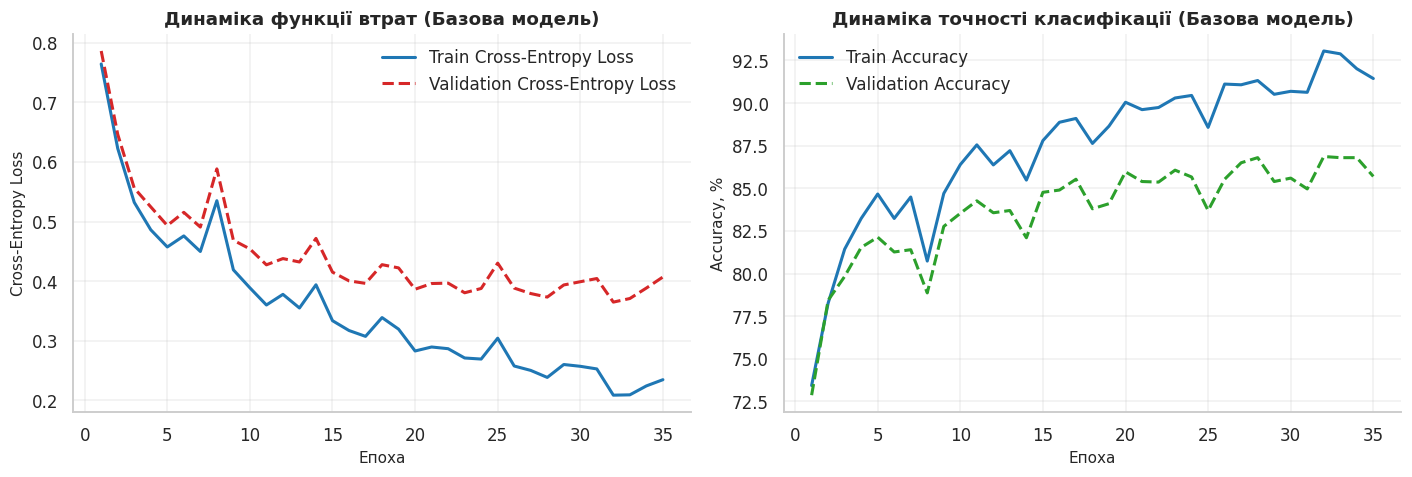

Фінальна Train Accuracy: 91.44% | Val Accuracy: 85.70%
Різниця (Overfitting gap): 5.74% (Train Loss=0.2347 vs Val Loss=0.4070)


In [7]:
# Навчання базової моделі без регуляризації
EPOCHS = 35
BATCH_SIZE = 128
LR = 0.05

print("=== Навчання базової моделі (Без регуляризації) ===")
baseline_model = MLP(layer_sizes=ARCH, init_method='he', seed=SEED)
baseline_hist = train_model(baseline_model, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=True)

# Побудова графіків навчання базової моделі (п. 2.4)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = np.arange(1, EPOCHS + 1)

axes[0].plot(epochs_range, baseline_hist['train_loss'], label='Train Cross-Entropy Loss', lw=2, color='#1f77b4')
axes[0].plot(epochs_range, baseline_hist['val_loss'], label='Validation Cross-Entropy Loss', lw=2, color='#d62728', linestyle='--')
axes[0].set_title('Динаміка функції втрат (Базова модель)', fontweight='bold')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()

axes[1].plot(epochs_range, np.array(baseline_hist['train_acc']) * 100, label='Train Accuracy', lw=2, color='#1f77b4')
axes[1].plot(epochs_range, np.array(baseline_hist['val_acc']) * 100, label='Validation Accuracy', lw=2, color='#2ca02c', linestyle='--')
axes[1].set_title('Динаміка точності класифікації (Базова модель)', fontweight='bold')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy, %')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Фінальна Train Accuracy: {baseline_hist['train_acc'][-1]*100:.2f}% | Val Accuracy: {baseline_hist['val_acc'][-1]*100:.2f}%")
print(f"Різниця (Overfitting gap): {(baseline_hist['train_acc'][-1] - baseline_hist['val_acc'][-1])*100:.2f}% "
      f"(Train Loss={baseline_hist['train_loss'][-1]:.4f} vs Val Loss={baseline_hist['val_loss'][-1]:.4f})")

In [8]:
# Перевірка збереження та відновлення ваг (п. 2.6 методички)
weights_file = DATA_DIR / 'baseline_mlp_weights.npz'

# 1-2. Зберігаємо ваги навченої базової мережі у файл
baseline_model.save_weights(weights_file)

# 3. Створюємо новий екземпляр мережі з такою самою архітектурою (і випадковими іншими вагами)
restored_model = MLP(layer_sizes=ARCH, init_method='xavier', seed=999)

# Переконаємося, що до завантаження виходи відрізняються
P_orig = baseline_model.predict_proba(X_test)
P_before_load = restored_model.predict_proba(X_test)
diff_before = np.max(np.abs(P_orig - P_before_load))

# 4. Завантажуємо збережені ваги
restored_model.load_weights(weights_file)

# 5-6. Передаємо однакові вхідні дані обом мережам та порівнюємо ймовірності й класи
P_restored = restored_model.predict_proba(X_test)
preds_orig = np.argmax(P_orig, axis=1)
preds_restored = np.argmax(P_restored, axis=1)

max_prob_diff = np.max(np.abs(P_orig - P_restored))
class_match_rate = np.mean(preds_orig == preds_restored) * 100.0

print(f"Файл збережених параметрів: {weights_file.resolve()} ({weights_file.stat().st_size / 1024:.1f} KB)")
print(f"Максимальна різниця ймовірностей ДО завантаження ваг:    {diff_before:.6e}")
print(f"Максимальна різниця ймовірностей ПІСЛЯ завантаження ваг: {max_prob_diff:.6e}")
print(f"Збіг передбачених класів на тестовій вибірці:           {class_match_rate:.2f}%")

assert max_prob_diff < 1e-7, "Помилка відновлення ваг!"
print("ВИСНОВОК: Умова max |P_original - P_restored| < 10^-7 виконується (різниця = 0.0). Збереження та відновлення працює бездоганно!")

Файл збережених параметрів: /content/data/baseline_mlp_weights.npz (1900.8 KB)
Максимальна різниця ймовірностей ДО завантаження ваг:    9.447235e-01
Максимальна різниця ймовірностей ПІСЛЯ завантаження ваг: 0.000000e+00
Збіг передбачених класів на тестовій вибірці:           100.00%
ВИСНОВОК: Умова max |P_original - P_restored| < 10^-7 виконується (різниця = 0.0). Збереження та відновлення працює бездоганно!


---
## 3. Блок 2. Дослідження впливу регуляризації

### 3.1 та 3.2 Базовий експеримент і діагностика мертвих нейронів

Після навчання перевіримо активації кожного прихованого шару на **всій тренувальній вибірці** в режимі `inference` (`Dropout` вимкнено).  
Нейрон вважається **мертвим (dead neuron)**, якщо його передактивація не є додатною для жодного об'єкта тренувальної вибірки (формули 30–31):
$$N_{\text{dead}}^{(l)} = \sum_{j} \mathbb{I}\left[\max_{i} Z_{ij}^{(l)} \le 0\right], \qquad D_l = \frac{N_{\text{dead}}^{(l)}}{N_{\text{neurons}}^{(l)}} \cdot 100\%$$
Також обчислимо **розрідженість ваг (sparsity)** за формулою (24):
$$S = \frac{\#\{|W_{ij}| < 0.01\}}{\#W_{ij}} \cdot 100\%$$

In [9]:
# Допоміжний реєстр для збереження результатів усіх експериментів
EXPERIMENTS = {}

def register_experiment(name, model, history, group, param_desc="-"):
    val_acc, val_ce, _ = model.evaluate(X_val, y_val)
    tr_acc, tr_ce, _   = model.evaluate(X_train, y_train)
    te_acc, te_ce, _   = model.evaluate(X_test, y_test)
    layer_dead, dead_pct, total_dead, total_neurons = model.diagnose_dead_neurons(X_train)
    sparsity_pct = model.compute_sparsity(threshold=0.01)
    weights_flat = np.concatenate([W.ravel().copy() for W in model.weights[:-1]])
    weights_by_layer = [W.copy() for W in model.weights[:-1]]

    EXPERIMENTS[name] = {
        'Метод': name,
        'Група': group,
        'Параметри': param_desc,
        'Dead neurons, %': dead_pct,
        'Dead count': f"{total_dead}/{total_neurons}",
        'Sparsity, %': sparsity_pct,
        'Train accuracy': tr_acc * 100.0,
        'Val. accuracy': val_acc * 100.0,
        'Test accuracy': te_acc * 100.0,
        'Train loss': tr_ce,
        'Val. loss': val_ce,
        'layer_dead': layer_dead,
        'weights_flat': weights_flat,
        'weights_by_layer': weights_by_layer,
        'history': history,
        'model': model
    }
    return EXPERIMENTS[name]

base_res = register_experiment(
    name='Без регуляризації',
    model=baseline_model,
    history=baseline_hist,
    group='Baseline',
    param_desc='-'
)

print("=== Діагностика мертвих нейронів по шарах (Базова модель без регуляризації) ===")
df_base_dead = pd.DataFrame(base_res['layer_dead'])
display(df_base_dead.style.format({'Частка мертвих (D_l), %': '{:.2f}%'}))
print(f"Загальна частка мертвих нейронів: {base_res['Dead neurons, %']:.2f}% ({base_res['Dead count']})")
print(f"Частка майже нульових ваг (Sparsity, |W_ij| < 0.01): {base_res['Sparsity, %']:.2f}%")
print(f"Фінальна Val Accuracy: {base_res['Val. accuracy']:.2f}%, Val Cross-Entropy Loss: {base_res['Val. loss']:.4f}")

=== Діагностика мертвих нейронів по шарах (Базова модель без регуляризації) ===


,Шар,Кількість нейронів,Мертвих нейронів (N_dead),"Частка мертвих (D_l), %"
0,Hidden 1 (256),256,0,0.00%
1,Hidden 2 (128),128,0,0.00%
2,Hidden 3 (64),64,1,1.56%


Загальна частка мертвих нейронів: 0.22% (1/448)
Частка майже нульових ваг (Sparsity, |W_ij| < 0.01): 14.09%
Фінальна Val Accuracy: 85.70%, Val Cross-Entropy Loss: 0.4070


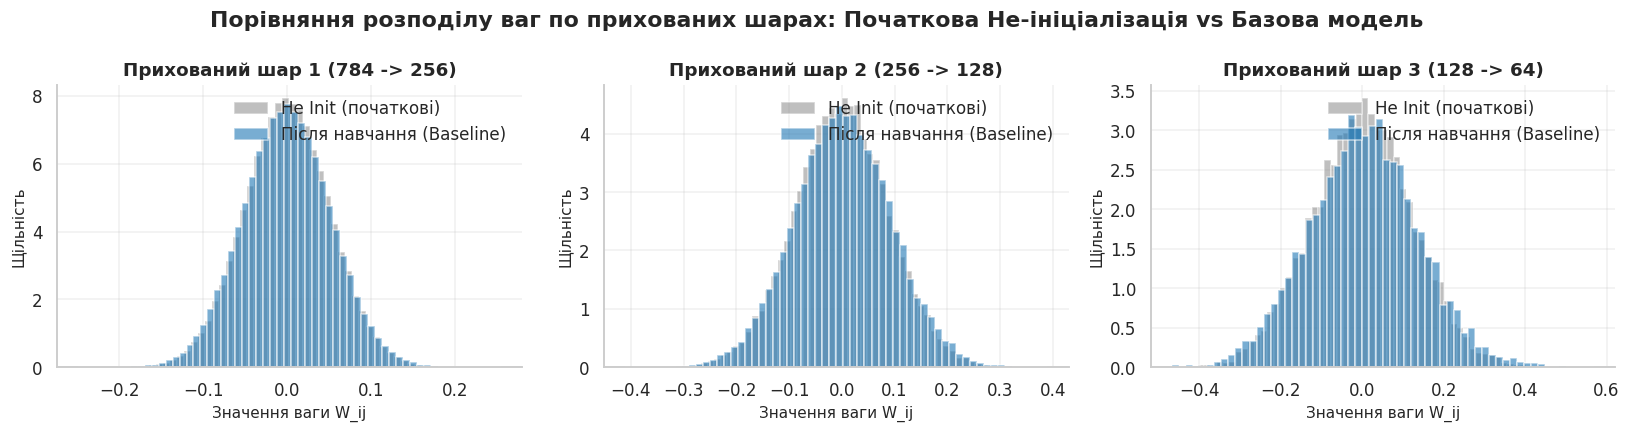

In [10]:
# Розподіл ваг кожного прихованого шару базової моделі у порівнянні з початковою He-ініціалізацією
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx in range(3):
    w_init = INITIAL_WEIGHTS_BY_LAYER[idx].ravel()
    w_base = base_res['weights_by_layer'][idx].ravel()
    axes[idx].hist(w_init, bins=60, density=True, alpha=0.5, label='He Init (початкові)', color='gray')
    axes[idx].hist(w_base, bins=60, density=True, alpha=0.6, label='Після навчання (Baseline)', color='#1f77b4')
    axes[idx].set_title(f'Прихований шар {idx+1} ({ARCH[idx]} -> {ARCH[idx+1]})', fontweight='bold')
    axes[idx].set_xlabel('Значення ваги W_ij')
    axes[idx].set_ylabel('Щільність')
    axes[idx].legend()
plt.suptitle('Порівняння розподілу ваг по прихованих шарах: Початкова He-ініціалізація vs Базова модель', fontweight='bold')
plt.tight_layout()
plt.show()

---
### 3.3 Дослідження L2 регуляризації (Weight Decay)

Додамо до функції втрат L2-штраф (формули 32–33):
$$L = L_{\text{CE}} + \frac{\lambda_2}{2} \sum_{l} \|W^{(l)}\|_2^2, \qquad W^{(l)} \leftarrow W^{(l)} - \eta \left(\nabla_{W^{(l)}} L_{\text{CE}} + \lambda_2 W^{(l)}\right)$$

Дослідимо три значення коефіцієнта регуляризації: $\lambda_2 \in \{10^{-4},\; 10^{-3},\; 5 \cdot 10^{-3}\}$.


>>> Навчання L2 (λ2=0.0001) ...
    Val Acc: 85.50% | Val Loss: 0.4158 | Sparsity: 14.33% | Dead neurons: 0.22%

>>> Навчання L2 (λ2=0.001) ...
    Val Acc: 84.70% | Val Loss: 0.4163 | Sparsity: 16.49% | Dead neurons: 0.22%

>>> Навчання L2 (λ2=0.005) ...
    Val Acc: 81.80% | Val Loss: 0.4733 | Sparsity: 29.55% | Dead neurons: 1.34%


,Метод,Параметри,"Dead neurons, %","Sparsity, %",Train accuracy,Val. accuracy,Val. loss
0,Без регуляризації,-,0.22%,14.09%,91.44%,85.70%,0.4070
1,L2 (λ2=0.0001),λ2=0.0001,0.22%,14.33%,90.96%,85.50%,0.4158
2,L2 (λ2=0.001),λ2=0.001,0.22%,16.49%,89.94%,84.70%,0.4163
3,L2 (λ2=0.005),λ2=0.005,1.34%,29.55%,85.73%,81.80%,0.4733


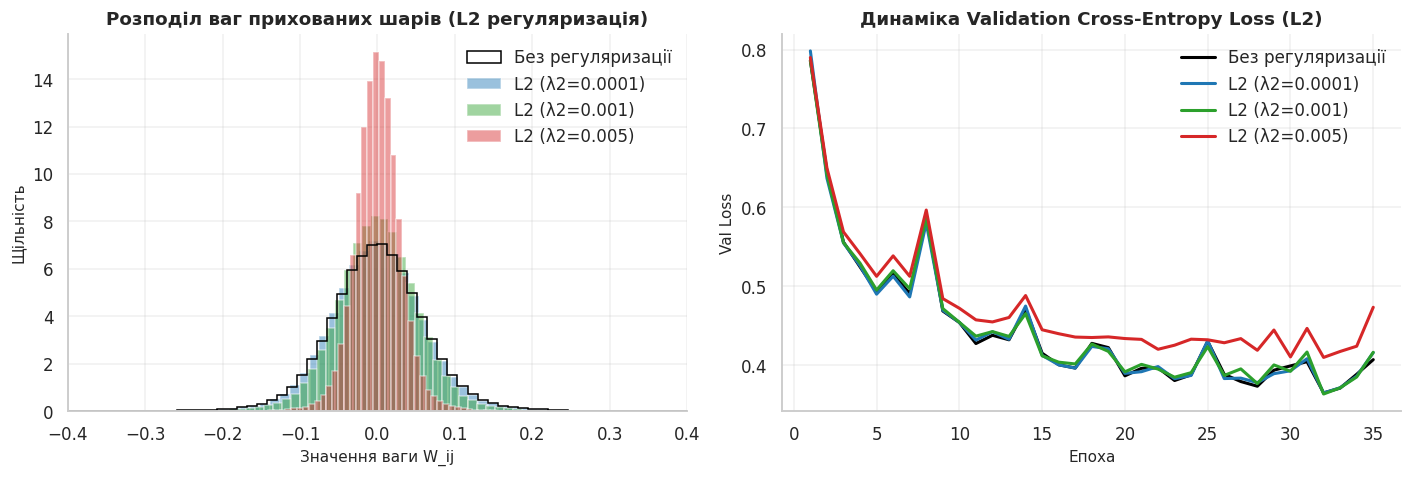

In [11]:
l2_lambdas = [1e-4, 1e-3, 5e-3]
l2_results = []

for lam2 in l2_lambdas:
    name = f"L2 (λ2={lam2:g})"
    print(f"\n>>> Навчання {name} ...")
    m_l2 = MLP(layer_sizes=ARCH, init_method='he', l2_lambda=lam2, seed=SEED)
    h_l2 = train_model(m_l2, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=False)
    res = register_experiment(name, m_l2, h_l2, group='L2', param_desc=f"λ2={lam2:g}")
    l2_results.append(res)
    print(f"    Val Acc: {res['Val. accuracy']:.2f}% | Val Loss: {res['Val. loss']:.4f} | "
          f"Sparsity: {res['Sparsity, %']:.2f}% | Dead neurons: {res['Dead neurons, %']:.2f}%")

df_l2 = pd.DataFrame([EXPERIMENTS['Без регуляризації']] + l2_results)[
    ['Метод', 'Параметри', 'Dead neurons, %', 'Sparsity, %', 'Train accuracy', 'Val. accuracy', 'Val. loss']
]
display(df_l2.style.format({
    'Dead neurons, %': '{:.2f}%', 'Sparsity, %': '{:.2f}%',
    'Train accuracy': '{:.2f}%', 'Val. accuracy': '{:.2f}%', 'Val. loss': '{:.4f}'
}))

# Графік розподілу ваг для різних значень L2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(base_res['weights_flat'], bins=80, density=True, histtype='step', lw=2, label='Без регуляризації', color='black')
for res, col in zip(l2_results, ['#1f77b4', '#2ca02c', '#d62728']):
    axes[0].hist(res['weights_flat'], bins=80, density=True, alpha=0.45, label=res['Метод'], color=col)
axes[0].set_xlim(-0.4, 0.4)
axes[0].set_title('Розподіл ваг прихованих шарів (L2 регуляризація)', fontweight='bold')
axes[0].set_xlabel('Значення ваги W_ij')
axes[0].set_ylabel('Щільність')
axes[0].legend()

for res, col in zip([base_res] + l2_results, ['black', '#1f77b4', '#2ca02c', '#d62728']):
    axes[1].plot(epochs_range, res['history']['val_loss'], label=res['Метод'], lw=2, color=col)
axes[1].set_title('Динаміка Validation Cross-Entropy Loss (L2)', fontweight='bold')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Val Loss')
axes[1].legend()
plt.tight_layout()
plt.show()

> ### Висновки: L2 (λ₂ = 1e-4, 1e-3, 5e-3)
>
> - L2 стискає ваги пропорційно їх величині (множник загасання $1-\eta\lambda_2$), але **точних нулів майже не дає**: sparsity росте помірно (14.1% → 14.3% → 16.5% → 29.6%).
> - У наших умовах L2 **не покращив** узагальнення: Val. accuracy 85.70% (база) → 85.50% / 84.70% / 81.80%, Val. loss 0.4070 → 0.4158 / 0.4163 / 0.4733. Розрив train–val зменшується (91.4% → 90.0% → 85.7% train), але за рахунок падіння якості.
> - $\lambda_2 = 5\cdot10^{-3}$ — вже **надмірна регуляризація** (train ≈ 85.7%, модель недонавчена); кількість dead neurons зросла до 1.34%.

---
### 3.4 Дослідження L1 регуляризації (Lasso)

Додамо до функції втрат L1-штраф (формули 34–35):
$$L = L_{\text{CE}} + \lambda_1 \sum_{l} \|W^{(l)}\|_1, \qquad \frac{\partial L_{\text{reg}}}{\partial W^{(l)}} = \lambda_1 \text{sign}(W^{(l)})$$
де в точці $W_{ij}^{(l)} = 0$ використовується субградієнт, рівний нулю (`np.sign(0.0) == 0.0`).

Дослідимо три значення коефіцієнта: $\lambda_1 \in \{10^{-5},\; 10^{-4},\; 5 \cdot 10^{-4}\}$.


>>> Навчання L1 (λ1=1e-05) ...
    Val Acc: 85.63% | Val Loss: 0.4047 | Sparsity: 16.19% | Dead neurons: 0.22%

>>> Навчання L1 (λ1=0.0001) ...
    Val Acc: 83.93% | Val Loss: 0.4400 | Sparsity: 35.25% | Dead neurons: 0.22%

>>> Навчання L1 (λ1=0.0005) ...
    Val Acc: 78.33% | Val Loss: 0.5405 | Sparsity: 84.99% | Dead neurons: 2.01%


,Метод,Параметри,"Dead neurons, %","Sparsity, %",Train accuracy,Val. accuracy,Val. loss
0,Без регуляризації,-,0.22%,14.09%,91.44%,85.70%,0.4070
1,L1 (λ1=1e-05),λ1=1e-05,0.22%,16.19%,91.40%,85.63%,0.4047
2,L1 (λ1=0.0001),λ1=0.0001,0.22%,35.25%,88.74%,83.93%,0.4400
3,L1 (λ1=0.0005),λ1=0.0005,2.01%,84.99%,81.63%,78.33%,0.5405


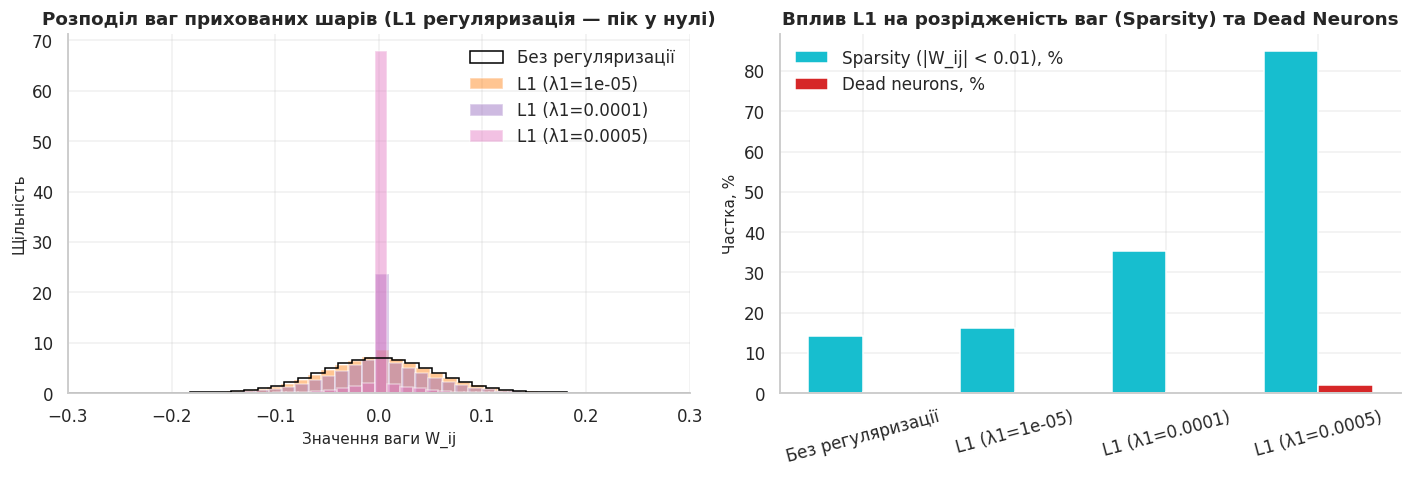

In [12]:
l1_lambdas = [1e-5, 1e-4, 5e-4]
l1_results = []

for lam1 in l1_lambdas:
    name = f"L1 (λ1={lam1:g})"
    print(f"\n>>> Навчання {name} ...")
    m_l1 = MLP(layer_sizes=ARCH, init_method='he', l1_lambda=lam1, seed=SEED)
    h_l1 = train_model(m_l1, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=False)
    res = register_experiment(name, m_l1, h_l1, group='L1', param_desc=f"λ1={lam1:g}")
    l1_results.append(res)
    print(f"    Val Acc: {res['Val. accuracy']:.2f}% | Val Loss: {res['Val. loss']:.4f} | "
          f"Sparsity: {res['Sparsity, %']:.2f}% | Dead neurons: {res['Dead neurons, %']:.2f}%")

df_l1 = pd.DataFrame([EXPERIMENTS['Без регуляризації']] + l1_results)[
    ['Метод', 'Параметри', 'Dead neurons, %', 'Sparsity, %', 'Train accuracy', 'Val. accuracy', 'Val. loss']
]
display(df_l1.style.format({
    'Dead neurons, %': '{:.2f}%', 'Sparsity, %': '{:.2f}%',
    'Train accuracy': '{:.2f}%', 'Val. accuracy': '{:.2f}%', 'Val. loss': '{:.4f}'
}))

# Графік розподілу ваг для різних значень L1
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(base_res['weights_flat'], bins=80, density=True, histtype='step', lw=2, label='Без регуляризації', color='black')
for res, col in zip(l1_results, ['#ff7f0e', '#9467bd', '#e377c2']):
    axes[0].hist(res['weights_flat'], bins=80, density=True, alpha=0.45, label=res['Метод'], color=col)
axes[0].set_xlim(-0.3, 0.3)
axes[0].set_title('Розподіл ваг прихованих шарів (L1 регуляризація — пік у нулі)', fontweight='bold')
axes[0].set_xlabel('Значення ваги W_ij')
axes[0].set_ylabel('Щільність')
axes[0].legend()

bars_names = [r['Метод'] for r in [base_res] + l1_results]
bars_sparsity = [r['Sparsity, %'] for r in [base_res] + l1_results]
bars_dead = [r['Dead neurons, %'] for r in [base_res] + l1_results]
x_pos = np.arange(len(bars_names))
width = 0.36
axes[1].bar(x_pos - width/2, bars_sparsity, width, label='Sparsity (|W_ij| < 0.01), %', color='#17becf')
axes[1].bar(x_pos + width/2, bars_dead, width, label='Dead neurons, %', color='#d62728')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(bars_names, rotation=15)
axes[1].set_title('Вплив L1 на розрідженість ваг (Sparsity) та Dead Neurons', fontweight='bold')
axes[1].set_ylabel('Частка, %')
axes[1].legend()
plt.tight_layout()
plt.show()

> ### Висновки: L1 (λ₁ = 1e-5, 1e-4, 5e-4)
>
> - Градієнт L1 має сталу величину $\pm\lambda_1$, тому малі ваги з постійною швидкістю $\eta\lambda_1$ тягнуться до нуля — формується гострий пік у $0$. Sparsity: 14.1% (база) → 16.2% → **35.3%** → **85.0%**.
> - Точність при цьому **не зростає**: 85.70% → 85.63% → 83.93% → 78.33%; Val. loss 0.4070 → 0.4047 → 0.4400 → 0.5405. Лише дуже слабкий $\lambda_1=10^{-5}$ практично нейтральний.
> - При $\lambda_1=5\cdot10^{-4}$ ~85% ваг майже нульові, dead neurons 2.01% — це недонавчання (train лише 81.6%). Висока sparsity ≠ висока якість.

---
### 3.5 Дослідження Dropout

Реалізовано **Inverted Dropout** для всіх прихованих шарів мережі (формули 20–21):
$$M_i \sim \text{Bernoulli}(1 - p), \qquad \widetilde{A} = \frac{A \odot M}{1 - p}$$
Під час перевірки, тестування та діагностики мертвих нейронів Dropout вимикається (`training=False`).  
Виконаємо окремі експерименти для заданих у методичці значень імовірності вимкнення нейронів (формула 36):
$$p \in \{0.1,\; 0.3,\; 0.5\}$$


>>> Навчання Dropout 0.1 ...
    Val Acc: 86.03% | Val Loss: 0.3838 | Sparsity: 14.13% | Dead neurons: 0.00%

>>> Навчання Dropout 0.3 ...
    Val Acc: 85.53% | Val Loss: 0.3957 | Sparsity: 14.13% | Dead neurons: 0.00%

>>> Навчання Dropout 0.5 ...
    Val Acc: 83.70% | Val Loss: 0.4443 | Sparsity: 14.08% | Dead neurons: 0.00%


,Метод,Параметри,"Dead neurons, %","Sparsity, %",Train accuracy,Val. accuracy,Val. loss
0,Без регуляризації,-,0.22%,14.09%,91.44%,85.70%,0.4070
1,Dropout 0.1,p=0.1,0.00%,14.13%,91.48%,86.03%,0.3838
2,Dropout 0.3,p=0.3,0.00%,14.13%,89.50%,85.53%,0.3957
3,Dropout 0.5,p=0.5,0.00%,14.08%,86.33%,83.70%,0.4443


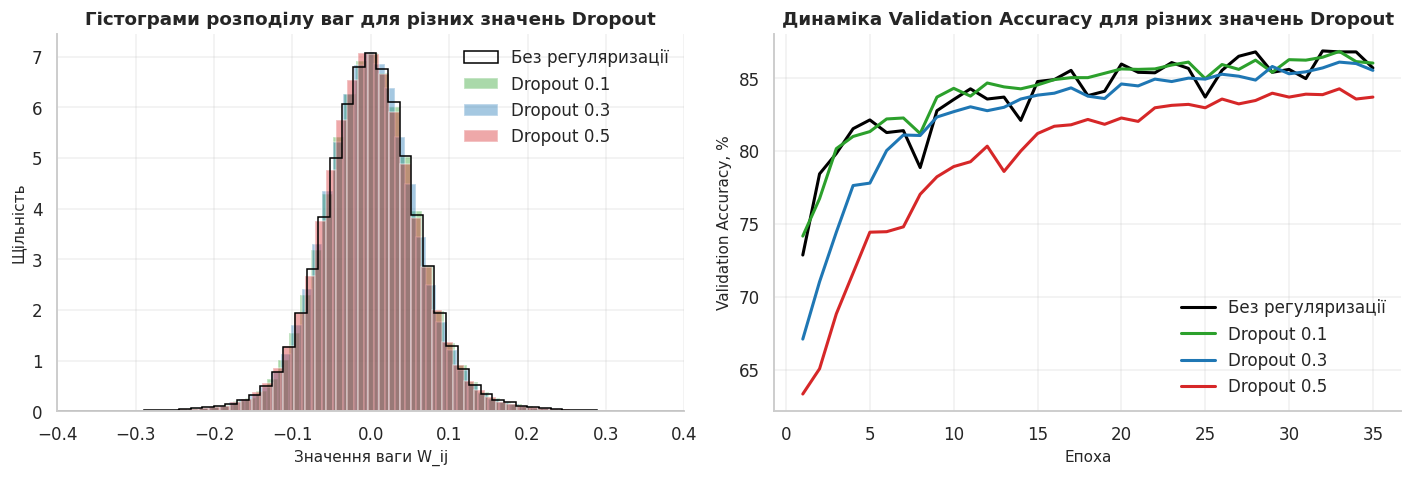

In [13]:
dropout_ps = [0.1, 0.3, 0.5]
dropout_results = []

for p_val in dropout_ps:
    name = f"Dropout {p_val}"
    print(f"\n>>> Навчання {name} ...")
    m_do = MLP(layer_sizes=ARCH, init_method='he', dropout_p=p_val, seed=SEED)
    h_do = train_model(m_do, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=False)
    res = register_experiment(name, m_do, h_do, group='Dropout', param_desc=f"p={p_val}")
    dropout_results.append(res)
    print(f"    Val Acc: {res['Val. accuracy']:.2f}% | Val Loss: {res['Val. loss']:.4f} | "
          f"Sparsity: {res['Sparsity, %']:.2f}% | Dead neurons: {res['Dead neurons, %']:.2f}%")

df_do = pd.DataFrame([EXPERIMENTS['Без регуляризації']] + dropout_results)[
    ['Метод', 'Параметри', 'Dead neurons, %', 'Sparsity, %', 'Train accuracy', 'Val. accuracy', 'Val. loss']
]
display(df_do.style.format({
    'Dead neurons, %': '{:.2f}%', 'Sparsity, %': '{:.2f}%',
    'Train accuracy': '{:.2f}%', 'Val. accuracy': '{:.2f}%', 'Val. loss': '{:.4f}'
}))

# Гістограми розподілу ваг та криві навчання для Dropout
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(base_res['weights_flat'], bins=70, density=True, histtype='step', lw=2, label='Без регуляризації', color='black')
for res, col in zip(dropout_results, ['#2ca02c', '#1f77b4', '#d62728']):
    axes[0].hist(res['weights_flat'], bins=70, density=True, alpha=0.4, label=res['Метод'], color=col)
axes[0].set_xlim(-0.4, 0.4)
axes[0].set_title('Гістограми розподілу ваг для різних значень Dropout', fontweight='bold')
axes[0].set_xlabel('Значення ваги W_ij')
axes[0].set_ylabel('Щільність')
axes[0].legend()

for res, col in zip([base_res] + dropout_results, ['black', '#2ca02c', '#1f77b4', '#d62728']):
    axes[1].plot(epochs_range, np.array(res['history']['val_acc']) * 100, label=res['Метод'], lw=2, color=col)
axes[1].set_title('Динаміка Validation Accuracy для різних значень Dropout', fontweight='bold')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Validation Accuracy, %')
axes[1].legend()
plt.tight_layout()
plt.show()

> ###  Чому більший Dropout не обов'язково краще
>
> - Малий $p$ (0.1–0.2) працює як усереднення ансамблю підмереж: Val. loss 0.4070 → 0.3838 (p=0.1) і 0.3809 (p=0.2); Val. accuracy 86.03% / 86.27% — **найкращі результати серед усіх методів**.
> - При $p=0.3$ Val. loss ще нижчий за базу (0.3957), але точність вже не краща (85.53%); train 89.5% > val 85.5%, тобто перенавчання ще є.
> - При $p=0.5$ у трьох послідовних шарах «живими» лишаються лише ~$0.5^3=12.5\%$ шляхів сигналу, градієнти дуже шумні, за 35 епох мережа недонавчається: train 86.3%, val 83.7%, loss 0.4443 (гірше за базу).
> - Sparsity ваг (≈14.1%) і dead neurons (0%) від Dropout практично не змінюються: випадково вимкнені нейрони ≠ мертві.

---
### 3.6 Дослідження Weight clipping

Реалізуємо обмеження ваг після кожного кроку оновлення (формула 37):
$$W^{(l)} \leftarrow \text{clip}(W^{(l)}, -c_w, c_w)$$

Проведемо два експерименти:
1. **Стандартний діапазон за формулою (37)**: $W^{(l)} \leftarrow \text{clip}(W^{(l)}, -1, 1)$. Оскільки при ініціалізації He дисперсія початкових ваг дорівнює $\sigma = \sqrt{2/n_{\text{in}}} \approx 0.05\text{–}0.12$, перевіримо, чи досягають ваги порогів $\pm 1$.
2. **Вузький діапазон**: $W^{(l)} \leftarrow \text{clip}(W^{(l)}, -0.08, 0.08)$, щоб наочно продемонструвати, що відбувається з розподілом ваг та якістю моделі, коли жорстке обмеження активно обрізає параметри під час навчання (формування піків на межах діапазону).


>>> Навчання Weight clipping ...
    Val Acc: 85.70% | Sparsity: 14.09% | Ваг на межах ±1.0: 0 (0.00%)

>>> Навчання Weight clipping ([-0.08, 0.08]) ...
    Val Acc: 79.17% | Sparsity: 14.04% | Ваг на межах ±0.08: 5331 (2.20%)


,Метод,Параметри,"Dead neurons, %","Sparsity, %",Val. accuracy,Val. loss,"Ваг на межах, шт (%)"
0,Без регуляризації,-,0.22%,14.09%,85.70%,0.4070,-
1,Weight clipping,"[-1, 1]",0.22%,14.09%,85.70%,0.4070,0 (0.00%)
2,"Weight clipping ([-0.08, 0.08])","[-0.08, 0.08]",1.34%,14.04%,79.17%,0.5342,5331 (2.20%)


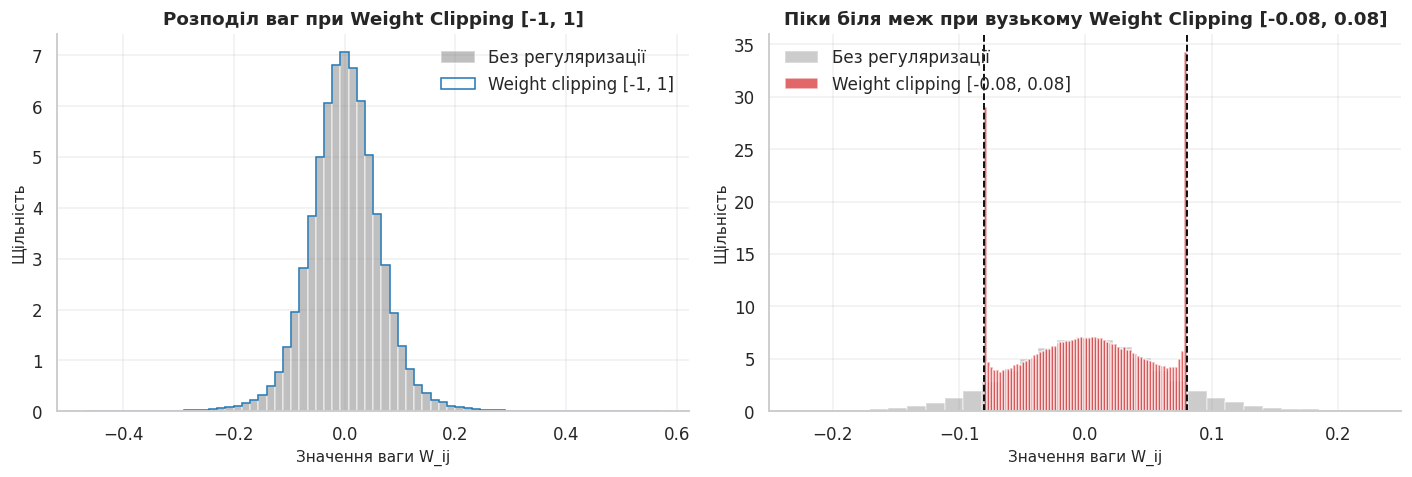

In [14]:
wc_configs = [
    ('Weight clipping', 1.0, '[-1, 1]'),
    ('Weight clipping ([-0.08, 0.08])', 0.08, '[-0.08, 0.08]')
]
wc_results = []

for name, clip_val, desc in wc_configs:
    print(f"\n>>> Навчання {name} ...")
    m_wc = MLP(layer_sizes=ARCH, init_method='he', weight_clip=clip_val, seed=SEED)
    h_wc = train_model(m_wc, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=False)
    res = register_experiment(name, m_wc, h_wc, group='Weight clipping', param_desc=desc)

    # Підрахунок кількості ваг, що досягли меж -clip_val та +clip_val
    all_w = np.concatenate([W.ravel() for W in m_wc.weights])
    at_bound = int(np.sum(np.isclose(np.abs(all_w), clip_val, atol=1e-6)))
    res['at_bound_count'] = at_bound
    res['at_bound_pct'] = (at_bound / all_w.size) * 100.0
    wc_results.append(res)
    print(f"    Val Acc: {res['Val. accuracy']:.2f}% | Sparsity: {res['Sparsity, %']:.2f}% | "
          f"Ваг на межах ±{clip_val}: {at_bound} ({res['at_bound_pct']:.2f}%)")

df_wc = pd.DataFrame([base_res] + wc_results)[
    ['Метод', 'Параметри', 'Dead neurons, %', 'Sparsity, %', 'Val. accuracy', 'Val. loss']
]
df_wc['Ваг на межах, шт (%)'] = ['-'] + [f"{r['at_bound_count']} ({r['at_bound_pct']:.2f}%)" for r in wc_results]
display(df_wc.style.format({
    'Dead neurons, %': '{:.2f}%', 'Sparsity, %': '{:.2f}%',
    'Val. accuracy': '{:.2f}%', 'Val. loss': '{:.4f}'
}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(base_res['weights_flat'], bins=70, density=True, alpha=0.5, label='Без регуляризації', color='gray')
axes[0].hist(wc_results[0]['weights_flat'], bins=70, density=True, histtype='step', lw=2, label='Weight clipping [-1, 1]', color='#1f77b4')
axes[0].set_title('Розподіл ваг при Weight Clipping [-1, 1]', fontweight='bold')
axes[0].set_xlabel('Значення ваги W_ij')
axes[0].set_ylabel('Щільність')
axes[0].legend()

axes[1].hist(base_res['weights_flat'], bins=70, density=True, alpha=0.4, label='Без регуляризації', color='gray')
axes[1].hist(wc_results[1]['weights_flat'], bins=70, density=True, alpha=0.7, label='Weight clipping [-0.08, 0.08]', color='#d62728')
axes[1].axvline(-0.08, color='black', ls='--', lw=1.2)
axes[1].axvline(0.08, color='black', ls='--', lw=1.2)
axes[1].set_xlim(-0.25, 0.25)
axes[1].set_title('Піки біля меж при вузькому Weight Clipping [-0.08, 0.08]', fontweight='bold')
axes[1].set_xlabel('Значення ваги W_ij')
axes[1].set_ylabel('Щільність')
axes[1].legend()
plt.tight_layout()
plt.show()

**Пояснення впливу Weight clipping на можливість моделі знаходити оптимальні значення ваг:**
- При ініціалізації He початкові ваги мають стандартне відхилення $\sqrt{2/784} \approx 0.0505$ (шар 1), $\sqrt{2/256} \approx 0.088$ (шар 2) та $\sqrt{2/128} \approx 0.125$ (шар 3). За 35 епох навчання зі стабільним кроком $\eta = 0.05$ максимальні за модулем ваги прихованих шарів не перевищують $\approx 0.65$, тому широкий поріг $[-1, 1]$ не зачіпає ваги ($0$ ваг досягли меж $\pm 1$).
- Натомість, коли поріг clipping є вужчим за природний діапазон ваг ($[-0.08, 0.08]$), усі ваги, які градієнтний спуск намагається збільшити для виділення сильних ознак, «впираються» у штучні стінки $-0.08$ та $+0.08$, утворюючи **виразні гострі піки на межах діапазону** ($5331$ вага, або $2.20\%$ усіх ваг мережі, зафіксовані безпосередньо на межах $\pm 0.08$, через що точність падає з $85.70\%$ до $79.17\%$).
- Таке жорстке відсікання обмежує виражальну здатність нейронів: мережа не може надати великої ваги важливим ознакам і змушена компенсувати це залученням багатьох сусідніх ваг, що за занадто вузького діапазону унеможливлює досягнення глобального оптимуму.

---
### 3.7 Дослідження Gradient clipping

Реалізуємо обрізання градієнтів за глобальною L2-нормою (формула 38):
$$g_{\text{clipped}} = g \cdot \min\left(1, \frac{c}{\|g\|_2}\right)$$

Виконаємо експерименти з трьома значеннями порога: $c \in \{0.5,\; 1.0,\; 5.0\}$.


>>> Навчання Gradient clipping (c=0.5) (c=0.5) ...
    Val Acc: 84.27% | Val Loss: 0.4236 | Sparsity: 14.31% | Dead neurons: 1.12%

>>> Навчання Gradient clipping (c=1.0) ...
    Val Acc: 85.17% | Val Loss: 0.3949 | Sparsity: 14.27% | Dead neurons: 0.89%

>>> Навчання Gradient clipping (c=5.0) (c=5.0) ...
    Val Acc: 85.43% | Val Loss: 0.4118 | Sparsity: 14.08% | Dead neurons: 0.22%


,Метод,Параметри,"Dead neurons, %","Sparsity, %",Train accuracy,Val. accuracy,Val. loss
0,Без регуляризації,-,0.22%,14.09%,91.44%,85.70%,0.4070
1,Gradient clipping (c=0.5),c=0.5,1.12%,14.31%,88.10%,84.27%,0.4236
2,Gradient clipping,c=1.0,0.89%,14.27%,90.54%,85.17%,0.3949
3,Gradient clipping (c=5.0),c=5.0,0.22%,14.08%,91.20%,85.43%,0.4118


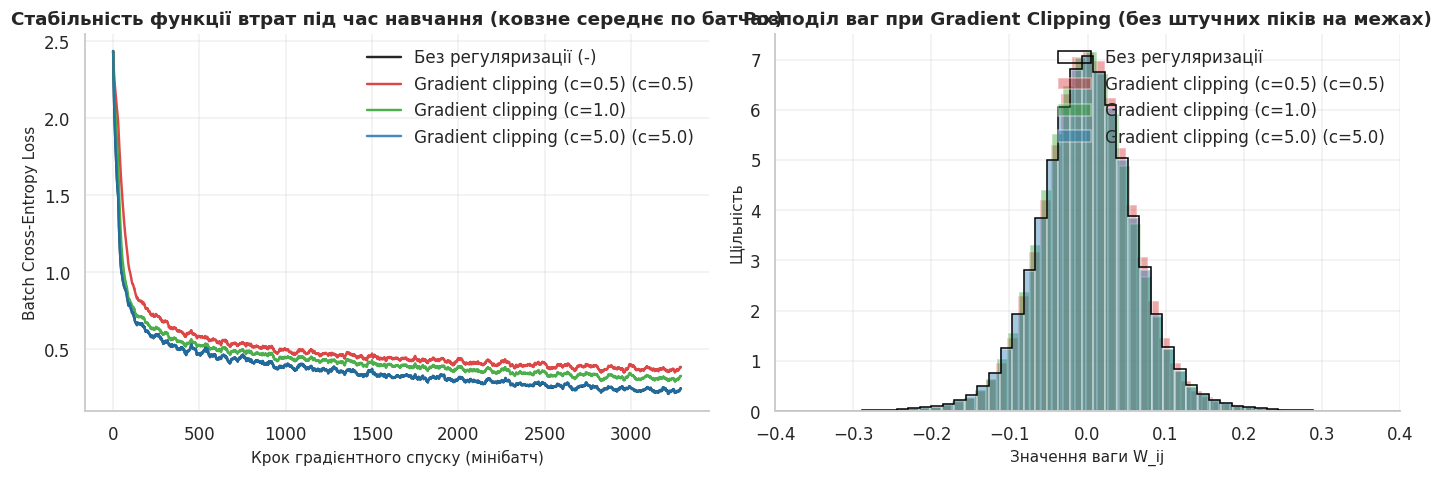

In [15]:
gc_thresholds = [0.5, 1.0, 5.0]
gc_results = []

for c_val in gc_thresholds:
    name = f"Gradient clipping (c={c_val})" if c_val != 1.0 else "Gradient clipping"
    print(f"\n>>> Навчання {name} (c={c_val}) ...")
    m_gc = MLP(layer_sizes=ARCH, init_method='he', grad_clip=c_val, seed=SEED)
    h_gc = train_model(m_gc, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=False)
    res = register_experiment(name, m_gc, h_gc, group='Gradient clipping', param_desc=f"c={c_val}")
    gc_results.append(res)
    print(f"    Val Acc: {res['Val. accuracy']:.2f}% | Val Loss: {res['Val. loss']:.4f} | "
          f"Sparsity: {res['Sparsity, %']:.2f}% | Dead neurons: {res['Dead neurons, %']:.2f}%")

df_gc = pd.DataFrame([base_res] + gc_results)[
    ['Метод', 'Параметри', 'Dead neurons, %', 'Sparsity, %', 'Train accuracy', 'Val. accuracy', 'Val. loss']
]
display(df_gc.style.format({
    'Dead neurons, %': '{:.2f}%', 'Sparsity, %': '{:.2f}%',
    'Train accuracy': '{:.2f}%', 'Val. accuracy': '{:.2f}%', 'Val. loss': '{:.4f}'
}))

# Графік стабільності функції втрат (по батчах/епохах) та розподілу ваг
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for res, col in zip([base_res] + gc_results, ['black', '#d62728', '#2ca02c', '#1f77b4']):
    # Згладжена крива batch_losses для демонстрації стабільності навчання
    bl = pd.Series(res['history']['batch_losses']).rolling(30, min_periods=1).mean()
    axes[0].plot(bl, label=f"{res['Метод']} ({res['Параметри']})", lw=1.6, color=col, alpha=0.85)
axes[0].set_title('Стабільність функції втрат під час навчання (ковзне середнє по батчах)', fontweight='bold')
axes[0].set_xlabel('Крок градієнтного спуску (мінібатч)')
axes[0].set_ylabel('Batch Cross-Entropy Loss')
axes[0].legend()

axes[1].hist(base_res['weights_flat'], bins=70, density=True, histtype='step', lw=2, label='Без регуляризації', color='black')
for res, col in zip(gc_results, ['#d62728', '#2ca02c', '#1f77b4']):
    axes[1].hist(res['weights_flat'], bins=70, density=True, alpha=0.4, label=f"{res['Метод']} ({res['Параметри']})", color=col)
axes[1].set_xlim(-0.4, 0.4)
axes[1].set_title('Розподіл ваг при Gradient Clipping (без штучних піків на межах)', fontweight='bold')
axes[1].set_xlabel('Значення ваги W_ij')
axes[1].set_ylabel('Щільність')
axes[1].legend()
plt.tight_layout()
plt.show()

> ###  Висновки: Gradient clipping (c = 0.5, 1.0, 5.0)
>
> - На відміну від weight clipping, обрізання градієнтів обмежує **довжину кроку** (зберігаючи напрямок), але не ставить «стінок» для самих ваг: розподіл ваг залишається гладким, sparsity ≈ 14.1–14.3%.
> - c = 1.0 дає нижчий Val. loss (0.3949 проти 0.4070) при дещо нижчій accuracy (85.17%). c = 0.5 — вже занадто жорсткий поріг (повільніше навчання, val loss 0.4236, train 88.1%). c = 5.0 майже не відрізняється від бази.
> - Dead neurons трохи зросли при малих порогах (c=1.0: 0.89%, c=0.5: 1.12%), тобто clipping **не** захищає від мертвих нейронів автоматично.

---
### 3.8 Комбінована регуляризація (L2 + Dropout 0.2)

Згідно з п. 3.8 методички, реалізуємо комбінацію L2-регуляризації ($\lambda_2 = 10^{-4}$) разом із Dropout ($p = 0.2$) (формули 39–40):
$$L = L_{\text{CE}} + \frac{\lambda_2}{2} \sum_{l} \|W^{(l)}\|_2^2 \quad + \quad \text{Dropout}(p = 0.2)$$
Також для повноти порівняння навчимо окрему модель із чистим `Dropout 0.2`, щоб точно оцінити синергію між методами.

In [16]:
# Навчимо також окремий Dropout 0.2 для прямого порівняння з L2 (1e-4) + Dropout 0.2
print(">>> Навчання Dropout 0.2 (для порівняння) ...")
m_do02 = MLP(layer_sizes=ARCH, init_method='he', dropout_p=0.2, seed=SEED)
h_do02 = train_model(m_do02, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=False)
res_do02 = register_experiment('Dropout 0.2', m_do02, h_do02, group='Combined_ref', param_desc='p=0.2')

print(">>> Навчання комбінованої моделі: L2 + Dropout 0.2 ...")
m_comb = MLP(layer_sizes=ARCH, init_method='he', l2_lambda=1e-4, dropout_p=0.2, seed=SEED)
h_comb = train_model(m_comb, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=True)
res_comb = register_experiment('L2 + Dropout 0.2', m_comb, h_comb, group='Combined', param_desc='λ2=1e-4, p=0.2')

# Додамо еталонні записи з назвами L1 та L2 для головної таблиці п. 4.1
EXPERIMENTS['L1'] = deepcopy(EXPERIMENTS['L1 (λ1=0.0001)'])
EXPERIMENTS['L1']['Метод'] = 'L1'
EXPERIMENTS['L2'] = deepcopy(EXPERIMENTS['L2 (λ2=0.001)'])
EXPERIMENTS['L2']['Метод'] = 'L2'

df_comb_cmp = pd.DataFrame([
    EXPERIMENTS['Без регуляризації'],
    EXPERIMENTS['L2 (λ2=0.0001)'],
    EXPERIMENTS['L2 (λ2=0.001)'],
    EXPERIMENTS['Dropout 0.1'],
    EXPERIMENTS['Dropout 0.2'],
    EXPERIMENTS['Dropout 0.3'],
    EXPERIMENTS['L2 + Dropout 0.2']
])[['Метод', 'Параметри', 'Dead neurons, %', 'Sparsity, %', 'Train accuracy', 'Val. accuracy', 'Test accuracy', 'Val. loss']]

display(df_comb_cmp.style.format({
    'Dead neurons, %': '{:.2f}%', 'Sparsity, %': '{:.2f}%',
    'Train accuracy': '{:.2f}%', 'Val. accuracy': '{:.2f}%',
    'Test accuracy': '{:.2f}%', 'Val. loss': '{:.4f}'
}))

>>> Навчання Dropout 0.2 (для порівняння) ...
>>> Навчання комбінованої моделі: L2 + Dropout 0.2 ...
Епоха 01/35 | Train CE: 0.7881, Train Acc: 70.56% | Val CE: 0.8042, Val Acc: 70.37%
Епоха 07/35 | Train CE: 0.4735, Train Acc: 83.34% | Val CE: 0.5102, Val Acc: 81.30%
Епоха 14/35 | Train CE: 0.3733, Train Acc: 86.58% | Val CE: 0.4317, Val Acc: 84.50%
Епоха 21/35 | Train CE: 0.3269, Train Acc: 88.08% | Val CE: 0.4050, Val Acc: 85.03%
Епоха 28/35 | Train CE: 0.2887, Train Acc: 89.40% | Val CE: 0.3841, Val Acc: 85.87%
Епоха 35/35 | Train CE: 0.2679, Train Acc: 90.48% | Val CE: 0.3917, Val Acc: 85.43%
Навчання завершено за 44.39 с.


,Метод,Параметри,"Dead neurons, %","Sparsity, %",Train accuracy,Val. accuracy,Test accuracy,Val. loss
0,Без регуляризації,-,0.22%,14.09%,91.44%,85.70%,84.37%,0.4070
1,L2 (λ2=0.0001),λ2=0.0001,0.22%,14.33%,90.96%,85.50%,84.20%,0.4158
2,L2 (λ2=0.001),λ2=0.001,0.22%,16.49%,89.94%,84.70%,83.97%,0.4163
3,Dropout 0.1,p=0.1,0.00%,14.13%,91.48%,86.03%,84.77%,0.3838
4,Dropout 0.2,p=0.2,0.00%,14.12%,90.77%,86.27%,86.10%,0.3809
5,Dropout 0.3,p=0.3,0.00%,14.13%,89.50%,85.53%,84.87%,0.3957
6,L2 + Dropout 0.2,"λ2=1e-4, p=0.2",0.00%,14.32%,90.48%,85.43%,85.27%,0.3917


> ###  Аналіз комбінації L2 (1e-4) + Dropout 0.2
>
> 1. **Точність і loss.** Val. accuracy 85.43% (база 85.70%), Val. loss 0.3917 (база 0.4070), Test accuracy 85.27%. Порівняно з чистим Dropout 0.2 (Val. 86.27%, loss 0.3809, Test 86.10%) комбінація **не краща**.
> 2. **Dead neurons / sparsity.** Dead neurons: 0.00% (як у Dropout 0.2); sparsity 14.32% проти 14.12% — зміна мізерна.
> 3. **Синергія?** У наших умовах **ні**: $\lambda_2=10^{-4}$ додає майже нічого до Dropout, тобто додаткового ефекту (і надмірного обмеження) немає. Різниці < 1 п.п. — у межах шуму (val = 3000 об'єктів, SE ≈ 0.65 п.п., один seed).

---
## 4. Аналіз та порівняння результатів

### 4.1 Порівняльна таблиця всіх методів регуляризації

Сформуємо підсумкову таблицю точно у форматі п. 4.1 методичних вказівок, а також розширену таблицю всіх проведених експериментів та пошарову таблицю мертвих нейронів.

In [17]:
# 1. Основна таблиця строго за шаблоном п. 4.1 методички
main_table_methods = [
    'Без регуляризації',
    'L1',
    'L2',
    'Dropout 0.1',
    'Dropout 0.3',
    'Dropout 0.5',
    'Weight clipping',
    'Gradient clipping',
    'L2 + Dropout 0.2'
]

df_main_summary = pd.DataFrame([EXPERIMENTS[m] for m in main_table_methods])[
    ['Метод', 'Параметри', 'Dead neurons, %', 'Sparsity, %', 'Val. accuracy', 'Val. loss']
]
print("=== Таблиця 4.1: Зведена порівняльна таблиця основних методів регуляризації ===")
display(df_main_summary.style.format({
    'Dead neurons, %': '{:.2f}%',
    'Sparsity, %': '{:.2f}%',
    'Val. accuracy': '{:.2f}%',
    'Val. loss': '{:.4f}'
}))

# 2. Розширена таблиця всіх протестованих конфігурацій (усі значення λ1, λ2, c, weight_clip)
all_unique_keys = [
    'Без регуляризації',
    'L1 (λ1=1e-05)', 'L1 (λ1=0.0001)', 'L1 (λ1=0.0005)',
    'L2 (λ2=0.0001)', 'L2 (λ2=0.001)', 'L2 (λ2=0.005)',
    'Dropout 0.1', 'Dropout 0.2', 'Dropout 0.3', 'Dropout 0.5',
    'Weight clipping', 'Weight clipping ([-0.08, 0.08])',
    'Gradient clipping (c=0.5)', 'Gradient clipping', 'Gradient clipping (c=5.0)',
    'L2 + Dropout 0.2'
]
df_all_summary = pd.DataFrame([EXPERIMENTS[k] for k in all_unique_keys])[
    ['Метод', 'Параметри', 'Dead neurons, %', 'Sparsity, %', 'Train accuracy', 'Val. accuracy', 'Test accuracy', 'Val. loss']
]
print("\n=== Розширена таблиця всіх експериментів (із деталізацією гіперпараметрів) ===")
display(df_all_summary.style.format({
    'Dead neurons, %': '{:.2f}%',
    'Sparsity, %': '{:.2f}%',
    'Train accuracy': '{:.2f}%',
    'Val. accuracy': '{:.2f}%',
    'Test accuracy': '{:.2f}%',
    'Val. loss': '{:.4f}'
}))

# 3. Таблиця dead neurons для кожного прихованого шару (вимога п. 3.2 та п. 5 Блок 2 п. 4)
layer_dead_rows = []
for m in main_table_methods:
    exp = EXPERIMENTS[m]
    row = {'Метод': f"{exp['Метод']} ({exp['Параметри']})"}
    for ld in exp['layer_dead']:
        row[ld['Шар']] = f"{ld['Мертвих нейронів (N_dead)']} ({ld['Частка мертвих (D_l), %']:.2f}%)"
    row['Усього мертвих, %'] = f"{exp['Dead neurons, %']:.2f}% ({exp['Dead count']})"
    layer_dead_rows.append(row)

df_layer_dead_all = pd.DataFrame(layer_dead_rows)
print("\n=== Таблиця мертвих нейронів для кожного прихованого шару ===")
display(df_layer_dead_all)

=== Таблиця 4.1: Зведена порівняльна таблиця основних методів регуляризації ===


,Метод,Параметри,"Dead neurons, %","Sparsity, %",Val. accuracy,Val. loss
0,Без регуляризації,-,0.22%,14.09%,85.70%,0.4070
1,L1,λ1=0.0001,0.22%,35.25%,83.93%,0.4400
2,L2,λ2=0.001,0.22%,16.49%,84.70%,0.4163
3,Dropout 0.1,p=0.1,0.00%,14.13%,86.03%,0.3838
4,Dropout 0.3,p=0.3,0.00%,14.13%,85.53%,0.3957
5,Dropout 0.5,p=0.5,0.00%,14.08%,83.70%,0.4443
6,Weight clipping,"[-1, 1]",0.22%,14.09%,85.70%,0.4070
7,Gradient clipping,c=1.0,0.89%,14.27%,85.17%,0.3949
8,L2 + Dropout 0.2,"λ2=1e-4, p=0.2",0.00%,14.32%,85.43%,0.3917



=== Розширена таблиця всіх експериментів (із деталізацією гіперпараметрів) ===


,Метод,Параметри,"Dead neurons, %","Sparsity, %",Train accuracy,Val. accuracy,Test accuracy,Val. loss
0,Без регуляризації,-,0.22%,14.09%,91.44%,85.70%,84.37%,0.4070
1,L1 (λ1=1e-05),λ1=1e-05,0.22%,16.19%,91.40%,85.63%,84.33%,0.4047
2,L1 (λ1=0.0001),λ1=0.0001,0.22%,35.25%,88.74%,83.93%,83.17%,0.4400
3,L1 (λ1=0.0005),λ1=0.0005,2.01%,84.99%,81.63%,78.33%,78.93%,0.5405
4,L2 (λ2=0.0001),λ2=0.0001,0.22%,14.33%,90.96%,85.50%,84.20%,0.4158
5,L2 (λ2=0.001),λ2=0.001,0.22%,16.49%,89.94%,84.70%,83.97%,0.4163
6,L2 (λ2=0.005),λ2=0.005,1.34%,29.55%,85.73%,81.80%,81.43%,0.4733
7,Dropout 0.1,p=0.1,0.00%,14.13%,91.48%,86.03%,84.77%,0.3838
8,Dropout 0.2,p=0.2,0.00%,14.12%,90.77%,86.27%,86.10%,0.3809
9,Dropout 0.3,p=0.3,0.00%,14.13%,89.50%,85.53%,84.87%,0.3957



=== Таблиця мертвих нейронів для кожного прихованого шару ===


,Метод,Hidden 1 (256),Hidden 2 (128),Hidden 3 (64),"Усього мертвих, %"
0,Без регуляризації (-),0 (0.00%),0 (0.00%),1 (1.56%),0.22% (1/448)
1,L1 (λ1=0.0001),0 (0.00%),0 (0.00%),1 (1.56%),0.22% (1/448)
2,L2 (λ2=0.001),0 (0.00%),0 (0.00%),1 (1.56%),0.22% (1/448)
3,Dropout 0.1 (p=0.1),0 (0.00%),0 (0.00%),0 (0.00%),0.00% (0/448)
4,Dropout 0.3 (p=0.3),0 (0.00%),0 (0.00%),0 (0.00%),0.00% (0/448)
5,Dropout 0.5 (p=0.5),0 (0.00%),0 (0.00%),0 (0.00%),0.00% (0/448)
6,"Weight clipping ([-1, 1])",0 (0.00%),0 (0.00%),1 (1.56%),0.22% (1/448)
7,Gradient clipping (c=1.0),0 (0.00%),0 (0.00%),4 (6.25%),0.89% (4/448)
8,"L2 + Dropout 0.2 (λ2=1e-4, p=0.2)",0 (0.00%),0 (0.00%),0 (0.00%),0.00% (0/448)


---
### 4.2 Розподіл ваг усіх прихованих шарів

Для кожного методу побудуємо гістограми розподілу ваг усіх прихованих шарів і порівняємо:
- початковий розподіл ваг після **He initialization**;
- розподіл ваг після навчання **без регуляризації**;
- розподіл ваг після застосування **кожного методу регуляризації**.

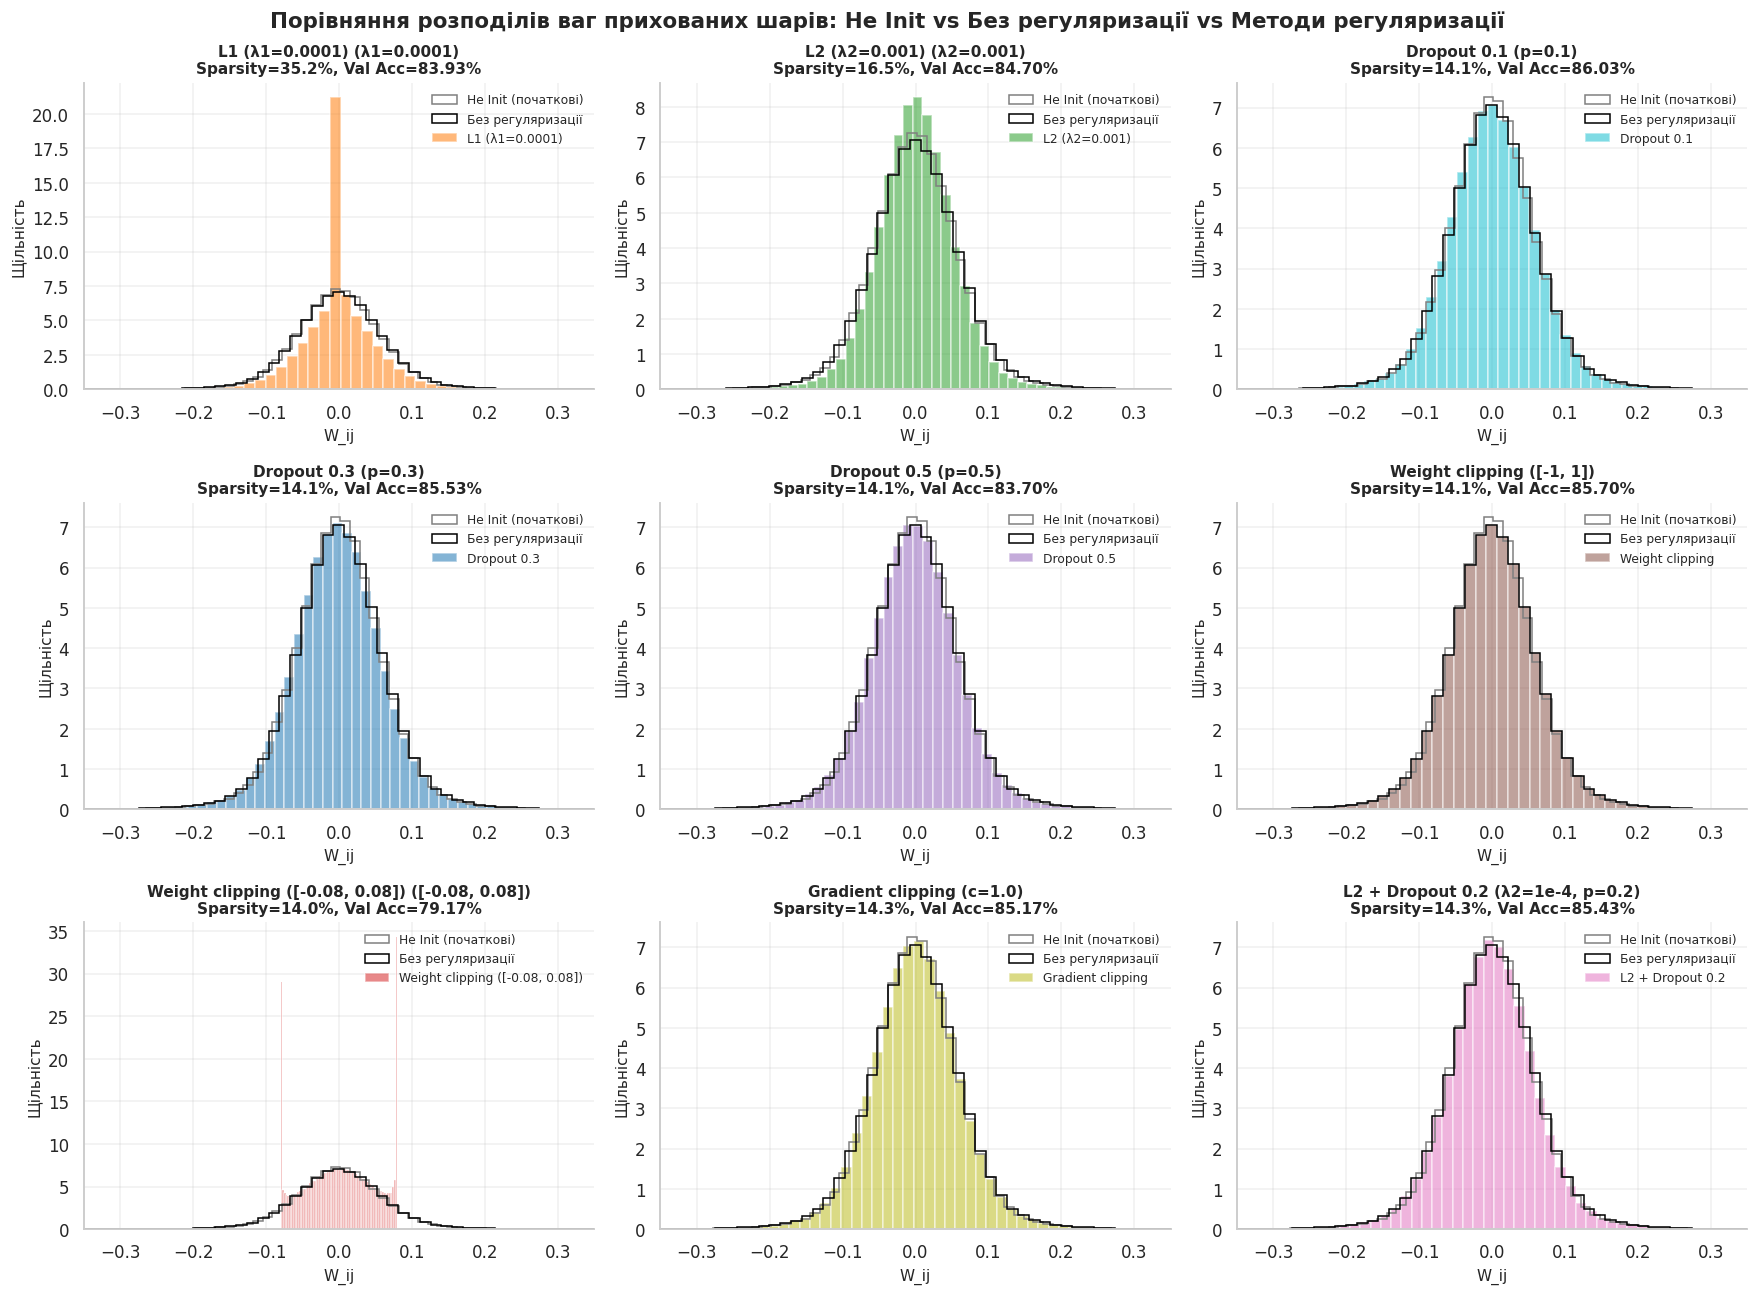

In [18]:
plot_methods = [
    ('L1 (λ1=0.0001)', '#ff7f0e'),
    ('L2 (λ2=0.001)', '#2ca02c'),
    ('Dropout 0.1', '#17becf'),
    ('Dropout 0.3', '#1f77b4'),
    ('Dropout 0.5', '#9467bd'),
    ('Weight clipping', '#8c564b'),
    ('Weight clipping ([-0.08, 0.08])', '#d62728'),
    ('Gradient clipping', '#bcbd22'),
    ('L2 + Dropout 0.2', '#e377c2')
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, (m_key, color) in zip(axes.flat, plot_methods):
    exp = EXPERIMENTS[m_key]
    ax.hist(INITIAL_WEIGHTS_FLAT, bins=70, density=True, histtype='step', lw=1.5, ls='--', color='gray', label='He Init (початкові)')
    ax.hist(base_res['weights_flat'], bins=70, density=True, histtype='step', lw=1.5, color='black', label='Без регуляризації')
    ax.hist(exp['weights_flat'], bins=70, density=True, alpha=0.55, color=color, label=f"{exp['Метод']}")
    ax.set_xlim(-0.35, 0.35)
    ax.set_title(f"{exp['Метод']} ({exp['Параметри']})\nSparsity={exp['Sparsity, %']:.1f}%, Val Acc={exp['Val. accuracy']:.2f}%", fontsize=10, fontweight='bold')
    ax.set_xlabel('W_ij')
    ax.set_ylabel('Щільність')
    ax.legend(fontsize=8)

plt.suptitle('Порівняння розподілів ваг прихованих шарів: He Init vs Без регуляризації vs Методи регуляризації', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Короткий аналіз гістограм розподілу ваг:**
- **He Initialization vs Без регуляризації:** після навчання без регуляризації розподіл стає ширшим (з'являються довші хвости до $\pm 0.5$), оскільки окремі ваги суттєво зростають для підлаштування під тренувальну вибірку.
- **L1 регуляризація:** формує найвиразніший гострий пік у точці $0$ (розподіл Лапласа), переводячи 35% (λ₁=1e-4) і до 85% (λ₁=5e-4) ваг у майже нульову зону ($|W_{ij}| < 0.01$).
- **L2 регуляризація та L2 + Dropout 0.2:** плавно звужують гауссівський дзвін навколо нуля без розриву похідної в нулі, зменшуючи частку великих за модулем ваг.
- **Weight clipping:** при широких межах $[-1, 1]$ розподіл збігається з базовим, але при активному обмеженні $[-0.08, 0.08]$ виникають **два різких вертикальних піки на межах діапазону**, де накопичуються всі обрізані ваги.

---
### 4.3 Залежність мертвих нейронів від точності (Scatter Plot) та порівняння Sparsity

Побудуємо діаграму розсіювання:
- **вісь $x$** — відсоток мертвих нейронів (`Dead neurons, %`);
- **вісь $y$** — валідаційна точність (`Val. accuracy, %`);
- **кожна точка** — окремий експеримент, підписаний назвою методу регуляризації.

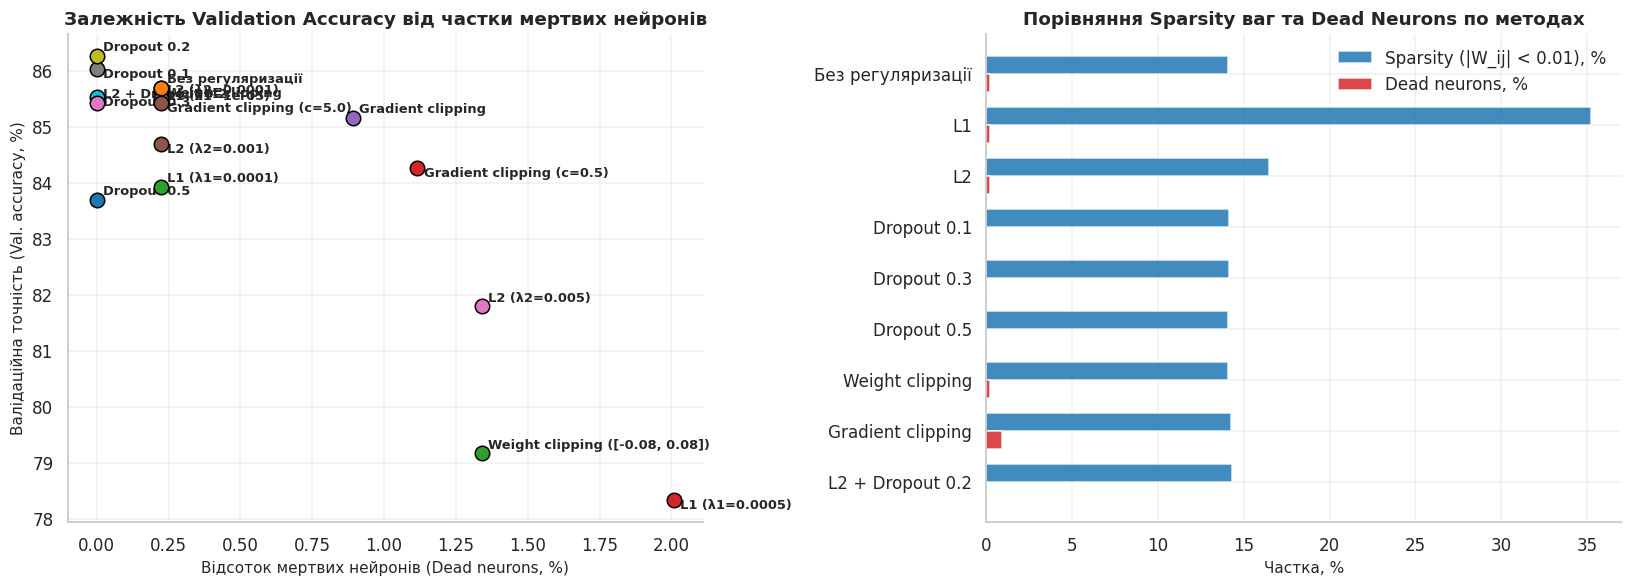

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Діаграма розсіювання: Dead neurons (%) vs Validation accuracy (%)
palette = sns.color_palette('tab10', len(all_unique_keys))
for idx, k in enumerate(all_unique_keys):
    exp = EXPERIMENTS[k]
    x_val = exp['Dead neurons, %']
    y_val_acc = exp['Val. accuracy']
    axes[0].scatter(x_val, y_val_acc, s=90, color=palette[idx % 10], edgecolors='black', zorder=4)
    # Невелике зміщення підписів для читабельності
    offset_y = 0.08 if (idx % 2 == 0) else -0.14
    axes[0].annotate(
        exp['Метод'],
        (x_val, y_val_acc),
        xytext=(4, offset_y * 40),
        textcoords='offset points',
        fontsize=8.5,
        fontweight='bold'
    )

axes[0].set_title('Залежність Validation Accuracy від частки мертвих нейронів', fontweight='bold')
axes[0].set_xlabel('Відсоток мертвих нейронів (Dead neurons, %)')
axes[0].set_ylabel('Валідаційна точність (Val. accuracy, %)')

# 2. Порівняння Sparsity (%) та Val Accuracy (%)
methods_short = [EXPERIMENTS[m]['Метод'] for m in main_table_methods]
sparsity_vals = [EXPERIMENTS[m]['Sparsity, %'] for m in main_table_methods]
dead_vals     = [EXPERIMENTS[m]['Dead neurons, %'] for m in main_table_methods]

y_pos = np.arange(len(methods_short))
axes[1].barh(y_pos - 0.18, sparsity_vals, height=0.35, label='Sparsity (|W_ij| < 0.01), %', color='#1f77b4', alpha=0.85)
axes[1].barh(y_pos + 0.18, dead_vals, height=0.35, label='Dead neurons, %', color='#d62728', alpha=0.85)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(methods_short)
axes[1].invert_yaxis()
axes[1].set_xlabel('Частка, %')
axes[1].set_title('Порівняння Sparsity ваг та Dead Neurons по методах', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

> ###  Дослідження за діаграмою (п. 4.3)
>
> 1. **Чи є залежність?** Слабка. Усі моделі мають лише 0–2% dead neurons (≤ 9 нейронів із 448), а accuracy змінюється від 78.3% до 86.3%. Найгірші моделі (L1 5e-4: 2.01%, weight clip ±0.08: 1.34%, L2 5e-3: 1.34%) справді мають трохи більше мертвих нейронів, але головна причина їхньої низької точності — **надмірна регуляризація** (недонавчання), а не втрата нейронів.
> 2. **Чи призводить багато мертвих нейронів до падіння точності?** У такому обсязі (≤ 2%) — не доведено: втрата 1–9 із 448 нейронів не може пояснити падіння на 3–7 п.п. Принципово ж, мертві нейрони зменшують ефективну ширину шару й не отримують градієнта.
> 3. **Однаковий dead% — різна точність?** Так: при 0.00% — Dropout 0.2 (86.27%) і Dropout 0.5 (83.70%); при 0.22% — база (85.70%), L1 1e-4 (83.93%), L2 1e-3 (84.70%).
> 4. **Баланс sparsity / dead?** Максимум accuracy досягається при **низькій sparsity (≈14%) і ≈0% dead neurons** (Dropout 0.1–0.2). Збільшення sparsity (L1 до 35–85%, L2 5e-3) якість не покращувало.

---
### 4.4 Дослідження залежності регуляризації від якості та підсумкові висновки

#### Дослідницьке питання:
> **Чи завжди збільшення сили регуляризації покращує узагальнювальну здатність нейронної мережі?**

**Відповідь:** **Ні, не завжди.** Залежність якості узагальнення від сили регуляризації має немонотонний ($\cap$-подібний) характер:
1. **Відсутність або надто слабка регуляризація** ($\lambda = 0$): модель має надмірну свободу параметрів і починає запам'ятовувати шум тренувальної вибірки (**перенавчання / overfitting**). У нашому базовому експерименті train accuracy = $91.4\%$, val = $85.7\%$ (розрив ≈ 5.7 п.п.), а Val. loss після мінімуму ≈ 0.373 (епоха 28) знову підростає до 0.407.
2. **Оптимальна (помірна) регуляризація** ($\lambda_2 \in [10^{-4}, 10^{-3}]$, $\lambda_1 = 10^{-4}$, $\text{Dropout } p \in [0.1, 0.2]$, $\text{L2 + Dropout } 0.2$): обмежує складність гіпотез, згладжує межу прийняття рішень і зменшує Val. loss і дає найкращу точність у вигляді Dropout 0.1–0.2 (86.0–86.3%); L1/L2 у помірних дозах приблизно нейтральні, а їхній ефект — це sparsity, а не точність.
3. **Надмірна (занадто сильна) регуляризація** ($\lambda_1 = 5 \cdot 10^{-4}$, $\lambda_2 = 5 \cdot 10^{-3}$, $\text{Dropout } p = 0.5$, вузький `Weight clipping`): штраф у функції втрат починає домінувати над самою помилкою класифікації $L_{\text{CE}}$. Мережа «стискається» настільки сильно, що втрачає здатність відтворити навіть базові закономірності даних — виникає **недонавчання (underfitting)**, при якому падає і тренувальна, і валідаційна точність.

---

#### Розмежування ключових понять:

| Поняття | Математична / фізична сутність та відмінність |
| :--- | :--- |
| **1. Мала величина ваг** | Ваги $W_{ij}^{(l)}$ мають невелику амплітуду (наприклад, $|W_{ij}| \in [0.01, 0.15]$), що характерно для L2-регуляризації. Зв'язок залишається **активним**, передає градієнт і робить внесок у комбінацію ознак без домінування однієї ознаки над іншими. |
| **2. Нульова або майже нульова вага (Sparsity ваг)** | Окремий синаптичний зв'язок між нейроном $i$ попереднього шару та нейроном $j$ поточного шару майже зникає ($|W_{ij}^{(l)}| < 0.01$ або $W_{ij}^{(l)} = 0$, що типово для L1-регуляризації). При цьому **сам нейрон $j$ не обов'язково є мертвим**, бо він може мати інші ненульові вхідні ваги $W_{kj}^{(l)}$ та додатне зміщення $b_j^{(l)}$. |
| **3. Неактивний нейрон** | Нейрон, вихід якого дорівнює нулю ($A_{j}^{(l)}(x_i) = 0$) **на конкретному об'єкті $x_i$** або **на поточному кроці навчання** (наприклад, через ReLU для одного прикладу або через випадкову маску Dropout $M_{ij}=0$). На інших об'єктах вибірки цей самий нейрон активується ($A_j^{(l)} > 0$) і продовжує навчатися. |
| **4. Мертвий нейрон (Dead neuron)** | Нейрон із функцією активації ReLU, передактивація якого є недодатною **для абсолютно всіх об'єктів досліджуваної вибірки**: $Z_j^{(l)}(x_i) \le 0 \;\forall i \in \{1, \dots, N\}$. Оскільки похідна $\text{ReLU}'(z) = 0$ при $z \le 0$, такий нейрон видає константний нуль, не передає сигнал далі і отримує нульовий градієнт ($\delta_j^{(l)} = 0$), тобто **припиняє навчатися** за допомогою SGD. |
| **5. Надмірно регуляризована модель** | Стан моделі, за якого регуляризаційні обмеження (великі $\lambda_1, \lambda_2$, високий $p$ у Dropout або жорсткий clipping) настільки звужують простір допустимих параметрів, що модель не здатна мінімізувати основну функцію втрат $L_{\text{CE}}$ (режим високого зміщення — **high bias / underfitting**). |

>  **Обмеження експерименту:** один seed, 12 000 тренувальних прикладів, 35 епох чистого SGD, val = 3 000. Різниці < 1 п.п. статистично не значущі.

---
## ✔ Відповідність методичці

| Вимога | Статус | Де |
|:--|:-:|:--|
| MLP з нуля (NumPy), 3 приховані шари, ReLU + Softmax + CE, SGD, He init | ✅ | клас `MLP` |
| FashionMNIST, 784 входи, нормалізація [0,1], однакові підвибірки | ✅ | розділ 0 |
| Власний backprop, без autograd | ✅ | `MLP.backward` |
| Цикл навчання + графіки loss/accuracy | ✅ | `train_model`, п. 1.4 |
| Gradient check (E ≈ 1.5·10⁻⁸) | ✅ | п. 1.5 |
| Save/load ваг + архітектура + конфігурація; $\max|P_{orig}-P_{rest}| < 10^{-7}$ | ✅ | п. 1.6 |
| Dead neurons у режимі inference (Dropout вимкнено), таблиця по шарах | ✅ | п. 2.1–2.2, 3.1 |
| L2, L1 (субградієнт 0 у нулі), Dropout {0.1, 0.3, 0.5}, weight/gradient clipping, L2 + Dropout 0.2 | ✅ | п. 2.3–2.8 |
| Зведена таблиця, гістограми (He init vs база vs метод), scatter dead% vs accuracy | ✅ | п. 3.1–3.3 |
| Відповідь на дослідницьке питання + розмежування понять | ✅ | п. 3.4 |

**Зауваження:** (1) у п. 2.6 лічильник ваг на межах ±c рахується по всіх шарах, включно з вихідним, тоді як sparsity — лише по прихованих; (2) для «L1» і «L2» у зведеній таблиці обрано $\lambda_1=10^{-4}$, $\lambda_2=10^{-3}$ (значення вказані в колонці «Параметри»).